# Dynamic and Hybrid Conditioning for Compositional Image Retrieval

**Deep Learning 2026 — Università di Trento**
Arianna Schiavi · Filippo Roseghini · nilo netti

---

**Abstract.** We address compositional image retrieval on CelebA: given a reference face and a set of textual conditions ($+$glasses, $-$red hair), retrieve images that satisfy all conditions while preserving the reference's identity. We propose a lightweight learned projection head that, given the CLIP embeddings of the reference and the conditions, produces a 512-dimensional displacement vector — replacing the naive latent-space arithmetic of the baseline. The module raises Recall@10 from 19.91% to 26.86% on a 101-query development set (+6.95pp, replicated on 5 seeds, all p < 0.0001), and scales to 36.62% with more training data and bagging. A systematic characterization reveals that the learned map is almost linear (R² ≈ 0.99), that 64% of the gain comes from conditioning on the reference image rather than from correcting the text directions, and that the method is limited to a closed vocabulary of training attributes. Twelve alternative hypotheses — including dynamic per-condition weighting, cross-attention fusion, and text direction repair — were measured and excluded with honest oracles and paired bootstrap tests.

---

*This notebook is the project submission. It contains the entire runnable code and the report, with the text interleaved between the cells. It runs end to end on Colab and locally, in a few minutes, and **trains the contribution from scratch**.*

---

## 0. Environment and imports

In [1]:
import os, subprocess, sys, time
from pathlib import Path
from urllib.request import urlretrieve

T_START = time.time()
IN_COLAB = "google.colab" in sys.modules

# ------------------------------------------------------------------ ACCOMPANYING MATERIALS
# This notebook carries all of its own code. What it cannot carry is the data: the frozen
# visual features of the three CelebA splits (458 MB), the evaluation file, the development
# set, and the result files of the training sessions reported in sec. 8. Extracting the
# features once and keeping them frozen is the intended way to work with this kind of
# pipeline; the code that produces them is in the appendix (sec. 11.1).
#
# Point MATERIALS_URL at the archive, or set DL_DATA, or place the folder next to this file.
MATERIALS_URL = ("https://github.com/filipporoseghini-cyber/dl-project-2026-materials"
                 "/releases/download/v1/materials.zip")
PROBE = "celeba_devset_valid.json"       # the file used to recognise the folder


def find_materials():
    """First location that looks like the materials folder, or None."""
    candidates = []
    if os.environ.get("DL_DATA"):
        candidates.append(Path(os.environ["DL_DATA"]))
    here = Path.cwd()
    candidates += [here, here.parent, here / "materials",
                   Path("/content/materials"), Path("/content")]
    return next((c for c in candidates if (c / PROBE).exists()), None)


ROOT = find_materials()

if ROOT is None and MATERIALS_URL:
    dest = Path("/content/materials") if IN_COLAB else Path("materials")
    dest.mkdir(parents=True, exist_ok=True)
    archive = dest / "materials.zip"
    print("downloading the materials, this takes a few minutes...", flush=True)
    urlretrieve(MATERIALS_URL, archive)
    subprocess.run(["unzip", "-q", "-o", str(archive), "-d", str(dest)], check=True)
    archive.unlink(missing_ok=True)
    ROOT = find_materials()

# The qualitative examples of sec. 8.5 need 91 CelebA images. They travel as a separate 1.1 MB
# asset rather than inside materials.zip, so that a failure here costs the three figures and
# not the notebook. The condition looks at the partition file because that is what
# find_celeba() uses to recognise the folder as a CelebA root.
IMAGES_URL = ("https://github.com/filipporoseghini-cyber/dl-project-2026-materials"
              "/releases/download/images-v1/images-bundle.zip")

if ROOT is not None and IMAGES_URL and not (ROOT / "datasets/celeba/list_eval_partition.txt").exists():
    try:
        _tmp = ROOT / "images-bundle.zip"
        urlretrieve(IMAGES_URL, _tmp)
        subprocess.run(["unzip", "-q", "-o", str(_tmp), "-d", str(ROOT)], check=True)
        _tmp.unlink(missing_ok=True)
    except Exception as _e:
        print(f"images      : download failed ({_e}); sec. 8.5 falls back to the textual reading")

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-U", "transformers"],
                   check=False)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

print(f"environment : {'Colab' if IN_COLAB else 'local'}")
if ROOT is None:
    print("materials   : NOT FOUND — set MATERIALS_URL above, or DL_DATA, or place the\n"
          "              folder next to this notebook. It must contain at least:\n"
          f"                {PROBE}, celeba_evaluation.json, embeddings/*.pt")
else:
    print(f"materials   : {ROOT}")

# Nothing below can run without the materials: stop here, with a message that says
# why, instead of three cells further down with an unexplained TypeError.
assert ROOT is not None, (
    "materials not found: set MATERIALS_URL in this cell, or set DL_DATA, or "
    "place the materials folder next to this notebook")

environment : local
materials   : <repo root>


### The evaluation protocol, included in full

Two modules *are* the project's protocol, and every number in this report comes from them. They
are reproduced verbatim in the next two cells rather than imported, so that the notebook carries
its own protocol and does not depend on any external module:

- **the benchmark** — reading the evaluation file, parsing the queries, and
  `build_benchmark_from_labels`, which reconstructs the same protocol on a different split. The
  reconstruction was verified to be **exact** against the provided file on 24/08: same sources,
  same ground truth. It is the reason the development set is comparable with the benchmark.
- **the development set and its uncertainty** — construction of the 101-query set, `macro`,
  `variance_decomposition`, `bootstrap_ci` and above all **`bootstrap_paired`**, the
  hierarchical paired bootstrap that every comparison in this report relies on.

Only the comments and the printed labels were translated from the working versions; the logic is
identical, which was checked by comparing the abstract syntax trees of the two files with all
string constants normalised.

The one addition made here at the measurement level is **Precision@K**, which the protocol
reports and which the project had never computed: `evaluate_per_source` discards the precision
value that `evaluate_query` already returns. The variant that keeps it is defined below.

In [2]:
# ============================================================================================
# THE EVALUATION PROTOCOL — 1/2: the benchmark
# Included verbatim so that this notebook is self-contained. The same code lives in
# the working module the project developed; only the comments were translated, the logic
# is byte-identical (verified by comparing the two abstract syntax trees).
# ============================================================================================
"""Evaluation on the official benchmark file (`celeba_evaluation.json`).

The ground truth and the list of source images are taken **as provided**, rather than
recomputed from the CelebA labels, because the protocol requires the evaluation to be
restricted to the source indices given in the file for each query.

Verified on 24/08/2026: the ground truth in the file coincides exactly with the one
reconstructed from the labels of our `celeba_test_clip_vitb32.pt` (zero differences over a
sample of simple and composed queries), so the indices in the file are aligned with the order
of the test split used to extract the embeddings.

The benchmark queries are multi-condition (up to 3 attributes).
"""

import json

import numpy as np
import torch


def parse_query_string(query, attr_to_idx):
    """'+Chubby, -Young' -> ([idx_Chubby], [idx_Young])"""
    pos, neg = [], []
    for token in query.split(","):
        token = token.strip()
        if not token:
            continue
        sign, name = token[0], token[1:].strip()
        if sign == "+":
            pos.append(attr_to_idx[name])
        elif sign == "-":
            neg.append(attr_to_idx[name])
        else:
            raise ValueError(f"Unrecognised sign in {token!r}")
    return pos, neg


def load_benchmark(json_path, attr_names):
    """Loads the official queries.

    Returns a list of dicts, one per entry of the file:
      query    : the original string, e.g. '+Chubby, -Young'
      pos, neg : lists of attribute indices
      queried  : pos + neg
      non_queried : the other attributes (the ones the Hamming constraint applies to)
      sources  : LongTensor [n_src] with the indices of the reference images
      gt       : list of sets, gt[i] = ground truth for sources[i]

    Note: the file contains 14 entries but '-Young' appears twice, identically (indices 4 and
    7), so the distinct queries are 13. Both are kept in order to follow the file to the
    letter; the macro-average is also reported over the distinct queries.
    """
    attr_to_idx = {name: i for i, name in enumerate(attr_names)}
    with open(json_path) as f:
        raw = json.load(f)

    benchmark = []
    for entry in raw:
        pos, neg = parse_query_string(entry["query"], attr_to_idx)
        queried = pos + neg
        gt_dict = entry["ground_truth"]
        sources = sorted(int(k) for k in gt_dict)
        benchmark.append({
            "query": entry["query"],
            "pos": pos,
            "neg": neg,
            "queried": queried,
            "non_queried": [i for i in range(len(attr_names)) if i not in queried],
            "sources": torch.tensor(sources, dtype=torch.long),
            "gt": [set(gt_dict[str(s)]) for s in sources],
        })
    return benchmark


def evaluate_query(build_query, entry, embeddings, k_values, batch_size=1024):
    """Evaluates a method on a single benchmark query.

    `build_query(ref_embs, entry) -> [n, D]` builds the query vectors for a batch of reference
    images; it must return them already L2-normalised.

    Returns (recall_per_source, precision_per_source): two dicts {k: np.array [n_src]}.
    """
    k_max = max(k_values)
    sources = entry["sources"]
    n_src = len(sources)

    recall = {k: np.zeros(n_src) for k in k_values}
    precision = {k: np.zeros(n_src) for k in k_values}

    for start in range(0, n_src, batch_size):
        stop = min(start + batch_size, n_src)
        batch_src = sources[start:stop]
        q_vecs = build_query(embeddings[batch_src], entry)
        sim = q_vecs @ embeddings.T                     # [b, N]
        # the reference cannot be a target: it is excluded before the topk
        sim[torch.arange(stop - start), batch_src] = -torch.inf
        top = sim.topk(k_max, dim=-1).indices.tolist()  # [b, k_max]

        for j, retrieved in enumerate(top):
            gt = entry["gt"][start + j]
            hits = np.array([idx in gt for idx in retrieved], dtype=bool)
            cum = hits.cumsum()
            for k in k_values:
                recall[k][start + j] = float(cum[k - 1] > 0)
                precision[k][start + j] = cum[k - 1] / k

    return recall, precision


def evaluate_benchmark(build_query, benchmark, embeddings, k_values,
                       batch_size=1024, verbose=True):
    """Evaluates a method on every benchmark query.

    Returns a list of dicts, one per query: query, n_src, recall {k: mean}, precision {k: mean}.
    """
    results = []
    for entry in benchmark:
        recall, precision = evaluate_query(build_query, entry, embeddings,
                                           k_values, batch_size)
        row = {
            "query": entry["query"],
            "n_src": len(entry["sources"]),
            "recall": {k: float(recall[k].mean()) for k in k_values},
            "precision": {k: float(precision[k].mean()) for k in k_values},
        }
        results.append(row)
        if verbose:
            r = "  ".join(f"R@{k}={row['recall'][k] * 100:5.1f}%" for k in k_values)
            print(f"  {row['query']:<45} n={row['n_src']:5d}  {r}")
    return results


def macro_average(results, k_values, unique_only=True):
    """Mean of the metrics across queries (macro-average: every query weighs the same).

    With `unique_only` the query duplicated in the file ('-Young') counts once.
    """
    rows = results
    if unique_only:
        seen, rows = set(), []
        for row in results:
            if row["query"] not in seen:
                seen.add(row["query"])
                rows.append(row)
    return (
        {k: float(np.mean([r["recall"][k] for r in rows])) for k in k_values},
        {k: float(np.mean([r["precision"][k] for r in rows])) for k in k_values},
    )


def print_comparison(named_results, k_values, unique_only=True):
    """Comparative Recall@K / Precision@K table across several methods.

    `named_results`: dict {method_name: output of evaluate_benchmark}.
    """
    names = list(named_results)
    col = max(12, max(len(n) for n in names) + 2)

    for metric, getter in (("Recall@K (hit rate)", 0), ("Precision@K", 1)):
        print(f"\n{metric} — macro-average over "
              f"{'13 distinct queries' if unique_only else '14 entries of the file'}")
        print("-" * (6 + col * len(names)))
        print(f"{'K':<6}" + "".join(f"{n:>{col}}" for n in names))
        avgs = {n: macro_average(named_results[n], k_values, unique_only)[getter]
                for n in names}
        for k in k_values:
            print(f"@{k:<5}" + "".join(f"{avgs[n][k] * 100:>{col - 1}.1f}%" for n in names))


def build_benchmark_from_labels(queries, labels, attr_names, hamming_threshold=2,
                                min_targets=5, max_sources=None, seed=0):
    """Rebuilds a benchmark with the same protocol as the official file on a different split
    (e.g. the validation set), starting from the labels alone.

    This is what makes it possible to tune hyperparameters **outside** the test set: the
    official file covers the test split only, and tuning on it would be overfitting the
    benchmark.

    It replicates the ground-truth rule exactly: a target is valid if it satisfies the +/-
    constraints, is within `hamming_threshold` of the reference on the non-queried attributes,
    and is not the reference itself; a source enters the benchmark only if it has at least
    `min_targets` valid targets.

    `queries` is a list of strings in the same format as the file ('+A, -B').
    """
    attr_to_idx = {name: i for i, name in enumerate(attr_names)}
    n_attr = len(attr_names)
    generator = torch.Generator().manual_seed(seed)

    benchmark = []
    for query in queries:
        pos, neg = parse_query_string(query, attr_to_idx)
        queried = pos + neg
        non_queried = [i for i in range(n_attr) if i not in queried]

        satisfies = torch.ones(len(labels), dtype=torch.bool)
        for i in pos:
            satisfies &= labels[:, i] == 1
        for j in neg:
            satisfies &= labels[:, j] == 0
        candidates = satisfies.nonzero(as_tuple=True)[0]

        # Rule for selecting the references, deduced from the official file and verified
        # exactly against all of its queries (24/08/2026): the reference must violate *every*
        # condition, not just one of them — for a positive attribute it must not have it, for
        # a negative one it must. The weaker rule ("does not already satisfy the query") gives
        # a superset of the official sources.
        violates_all = torch.ones(len(labels), dtype=torch.bool)
        for i in pos:
            violates_all &= labels[:, i] == 0
        for j in neg:
            violates_all &= labels[:, j] == 1
        refs = violates_all.nonzero(as_tuple=True)[0]
        if max_sources is not None and len(refs) > max_sources:
            refs = refs[torch.randperm(len(refs), generator=generator)[:max_sources]]

        cand_nq = labels[candidates][:, non_queried].bool()
        sources, gt = [], []
        for start in range(0, len(refs), 256):   # in blocks: the Hamming matrix is [b, n_cand]
            block = refs[start:start + 256]
            ref_nq = labels[block][:, non_queried].bool()
            hamming = (cand_nq.unsqueeze(0) != ref_nq.unsqueeze(1)).sum(dim=2)
            for j, ref in enumerate(block.tolist()):
                valid = candidates[hamming[j] <= hamming_threshold]
                valid = valid[valid != ref]
                if len(valid) >= min_targets:
                    sources.append(ref)
                    gt.append(set(valid.tolist()))

        if sources:
            benchmark.append({
                "query": query,
                "pos": pos,
                "neg": neg,
                "queried": queried,
                "non_queried": non_queried,
                "sources": torch.tensor(sources, dtype=torch.long),
                "gt": gt,
            })
    return benchmark

In [3]:
# ============================================================================================
# THE EVALUATION PROTOCOL — 2/2: development set and uncertainty
# As above, minus the import, since the functions it needs are defined in the cell above.
# ============================================================================================
"""Extended development set, and quantification of uncertainty.

WHY. The official benchmark has 13 distinct queries. On that basis a difference of less than a
percentage point between two methods is not distinguishable from noise: that is exactly what
produced the false positive on the positive/negative asymmetry earlier in the project (+0.48pp
on the development set, -0.20pp on the test set).

WHERE THE NOISE IS. Measured on the official benchmark (ortho-text method, alpha=2.0,
Recall@10), the macro-average has two sources of uncertainty:

    standard deviation ACROSS queries   9.30pp
    standard error of the macro-average 2.58pp   <- sampling of the queries
    standard error from sources alone   0.51pp   <- sampling of the sources

There are 27,697 sources: the uncertainty they introduce is five times smaller than the one due
to having only 13 queries. A bootstrap over the sources alone, which is what one would be
tempted to do, therefore produces confidence intervals that are far too narrow and would **not**
have caught the false positive. The right sampling unit is the query, not the source.

WHAT THIS MODULE DOES.
1. Generates a development set of ~100 queries on the validation split, with the same
   distribution as the official benchmark, reusing `build_benchmark_from_labels` (verified to
   be exact against the official file).
2. Serialises it in the same schema as the official file, so that it is readable with
   `load_benchmark`.
3. Provides a hierarchical bootstrap (query, then source) and its **paired** version, for
   comparing two methods on the same queries.

The criterion of success is not a higher Recall: it is being able to state that a difference
between two methods is real.
"""

import json

import numpy as np
import torch

# Composition of the official benchmark, measured on the 13 distinct queries
# (7 with one condition, 4 with two, 2 with three; 13 positive conditions out of 21).
N_COND_WEIGHTS = (0.54, 0.31, 0.15)
P_POSITIVE = 0.62


def attribute_auc(embeddings, labels, directions, attr_names):
    """AUC of the zero-shot classification of each attribute with CLIP's textual direction.
    To be computed on the **train split**, disjoint from valid and test, so as to contaminate
    neither the development set nor the benchmark.
    """
    scores = embeddings @ directions.T
    auc = {}
    for i, name in enumerate(attr_names):
        y = labels[:, i].numpy().astype(bool)
        s = scores[:, i].numpy()
        n_pos, n_neg = int(y.sum()), int((~y).sum())
        if n_pos < 50 or n_neg < 50:
            auc[name] = float("nan")
            continue
        rank = np.argsort(np.argsort(s)) + 1.0
        auc[name] = float((rank[y].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))
    return auc


def attribute_pool(auc, min_auc=0.55):
    """Attributes admitted into the query sampling.

    Excluded are those whose textual direction is uncorrelated or **anti**-correlated with the
    label (Sideburns 0.32, Rosy_Cheeks 0.41, 5_o_Clock_Shadow 0.42, ...): on those queries every
    method stays at zero, and queries where all methods fail in the same way add noise to the
    macro-average without adding discriminating power.

    The 0.55 threshold is chosen so as to include all twelve attributes that appear in the
    official benchmark: the weakest is Wearing_Lipstick (0.568), followed by Heavy_Makeup
    (0.598). The filter therefore aligns the development set with the population of queries the
    benchmark is drawn from, instead of restricting it to the easy attributes.

    CAUTION: the criterion depends on the **textual** directions. It does not bias a comparison
    between methods that share those directions (baseline, ortho, weighting variants) — it only
    removes queries that are at the floor for everyone — but it must not be used to compare
    textual directions against visual ones.
    """
    return [name for name, value in auc.items() if value == value and value >= min_auc]


def sample_queries(pool, n_queries, n_cond, exclude=(), seed=2026,
                   p_positive=P_POSITIVE):
    """Random queries with `n_cond` conditions each.

    `exclude` keeps out the queries already present elsewhere (typically the 13 official ones,
    which are added separately as a subset).

    The space of queries with `n_cond` conditions is finite and, for n_cond = 1, **small**: with
    29 attributes in the pool there are only 29 x 2 = 58 one-condition queries, minus the 7
    official ones already excluded. Asking for more than exist would stall the rejection
    sampling, so the request is capped at the available space and there is a limit on attempts
    anyway. The function may return fewer than `n_queries`: it is up to the caller to decide
    what to do about it.
    """
    import random
    from math import comb

    space = comb(len(pool), n_cond) * (2 ** n_cond)
    rng = random.Random(seed)
    seen = set(exclude)
    queries = []
    attempts, max_attempts = 0, 200 * max(n_queries, 1)
    while len(queries) < min(n_queries, space) and attempts < max_attempts:
        attempts += 1
        attrs = rng.sample(pool, n_cond)
        query = ", ".join(
            f"{'+' if rng.random() < p_positive else '-'}{a}" for a in attrs
        )
        if query in seen:
            continue
        seen.add(query)
        queries.append(query)
    return queries


def build_devset(queries, labels, attr_names, min_sources=30, max_sources=1200,
                 max_final_sources=400, seed=7, verbose=True, **kwargs):
    """Builds the entries, discards the degenerate queries and evens out the number of
    references per query.

    `max_sources` limits the references **before** the Hamming filter, so only a fraction
    (~20-30%) survives: it is the parameter that governs the cost, O(references x candidates)
    per query.

    `max_final_sources` subsamples the surviving references. This is not a loss: with ~400
    references the within-query standard error is about 1.8pp, which averaged over ~100 queries
    becomes 0.18pp — an order of magnitude below the uncertainty due to sampling the queries,
    which is the one that matters. Keeping more would only inflate the file and the evaluation
    time, and would let common queries weigh more in the within-query precision.

    `min_sources` discards queries with too few valid references, whose estimates are too noisy
    to be useful. On the official benchmark three queries out of thirteen fall into this
    condition ('-Male, -Mustache' with 27 sources, '+Wearing_Lipstick, ...' with 34,
    '-Smiling, ...' with 79).
    """
    bench = build_benchmark_from_labels(queries, labels, attr_names,
                                        max_sources=max_sources, seed=seed, **kwargs)
    kept = [e for e in bench if len(e["sources"]) >= min_sources]
    if max_final_sources is not None:
        generator = torch.Generator().manual_seed(seed)
        for e in kept:
            if len(e["sources"]) > max_final_sources:
                pick = torch.randperm(len(e["sources"]), generator=generator)[:max_final_sources]
                pick = pick.sort().values
                e["sources"] = e["sources"][pick]
                e["gt"] = [e["gt"][i] for i in pick.tolist()]
    if verbose:
        print(f"    {len(bench)}/{len(queries)} queries with at least one valid reference; "
              f"{len(kept)} with >= {min_sources} references")
    return kept


def build_stratified_devset(pool, labels, attr_names, targets, exclude=(),
                            batch=40, max_rounds=12, seed=2026, verbose=True, **kwargs):
    """Development set with the composition of the official benchmark guaranteed.

    Sampling according to the official distribution and *then* filtering the degenerate queries
    is not enough: queries with more conditions have far fewer valid references, so they survive
    less often and the final composition drifts towards the simple ones (in one attempt:
    51/41/8 instead of 54/31/15). Here the sampling is done at fixed quotas, one group at a
    time, until every stratum reaches its own quota.

    `targets` is a dict {n_conditions: n_queries_wanted}. A stratum may close **below quota** if
    its query space runs out: this happens at n_cond = 1, where only 58 queries are possible and
    not all survive the filter on degenerate queries. In that case we take what there is, and
    the final composition must be reported as measured, not as intended.
    """
    kept = {n: [] for n in targets}
    seen = set(exclude)
    for n_cond, target in targets.items():
        for round_i in range(max_rounds):
            if len(kept[n_cond]) >= target:
                break
            need = target - len(kept[n_cond])
            queries = sample_queries(pool, max(batch, 2 * need), n_cond,
                                     exclude=seen, seed=seed + 100 * n_cond + round_i)
            if not queries:            # space exhausted: no point insisting
                if verbose:
                    print(f"  {n_cond} conditions: space exhausted at round {round_i + 1}")
                break
            seen.update(queries)
            if verbose:
                print(f"  {n_cond} conditions, round {round_i + 1}: {len(queries)} attempted")
            kept[n_cond] += build_devset(queries, labels, attr_names,
                                         seed=seed, verbose=verbose, **kwargs)
        kept[n_cond] = kept[n_cond][:target]
        if verbose:
            flag = "" if len(kept[n_cond]) >= target else "   <- below quota"
            print(f"  {n_cond} conditions: {len(kept[n_cond])}/{target}{flag}")
    return [e for n in sorted(kept) for e in kept[n]]


def save_devset(bench, path):
    """Serialises in the same schema as the official file, so that the development set can be
    read back with `load_benchmark` and kept alongside the other
    result files.
    """
    # the sources are written in sorted order because `load_benchmark` reorders them on read:
    # this way the JSON round trip is exact, entry by entry.
    payload = [
        {
            "query": e["query"],
            "ground_truth": {
                str(int(src)): sorted(int(t) for t in gt)
                for src, gt in sorted(zip(e["sources"].tolist(), e["gt"]),
                                      key=lambda pair: pair[0])
            },
        }
        for e in bench
    ]
    with open(path, "w") as f:
        json.dump(payload, f)
    return path


# --------------------------------------------------------------------------
# Evaluation with uncertainty
# --------------------------------------------------------------------------

def evaluate_per_source(build_query, bench, embeddings, k_values, batch_size=2048):
    """Like `evaluate_benchmark`, but keeps the value **per individual source** instead of
    averaging it straight away: it is the raw material the bootstrap needs.

    Returns {k: [array [n_src] for each query]}.
    """
    per_source = {k: [] for k in k_values}
    for entry in bench:
        recall, _ = evaluate_query(build_query, entry, embeddings, k_values, batch_size)
        for k in k_values:
            per_source[k].append(recall[k])
    return per_source


def macro(per_source_k):
    """Macro-average: every query weighs the same, as in the official protocol."""
    return float(np.mean([v.mean() for v in per_source_k]))


def variance_decomposition(per_source_k):
    """Separates the two sources of uncertainty of the macro-average.

    Returns a dict with the standard deviation across queries, the standard error due to
    sampling the queries and the one due to the sources. It shows which of the two dominates —
    and therefore which one has to be reduced.
    """
    means = np.array([v.mean() for v in per_source_k])
    n = np.array([len(v) for v in per_source_k])
    q = len(means)
    se_within = np.sqrt(np.sum(means * (1 - means) / n)) / q
    return {
        "n_query": q,
        "n_source": int(n.sum()),
        "macro": float(means.mean()),
        "sd_between_query": float(means.std(ddof=1)),
        "se_query": float(means.std(ddof=1) / np.sqrt(q)),
        "se_source": float(se_within),
    }


def bootstrap_ci(per_source_k, n_boot=5000, alpha=0.05, stage="both", seed=0):
    """Confidence interval on the macro-average, by percentiles.

    Hierarchical bootstrap: the queries are resampled with replacement and, within each of
    them, its sources. Since the per-source value is binary, resampling the sources has a
    closed form — the resampled mean is Binomial(n_q, r_q)/n_q — so the resamples do not need
    to be materialised.

    `stage` isolates the two sources:
      'both'   query + source (default, the real uncertainty)
      'query'  queries only
      'source' sources only (what one would get by bootstrapping the sources alone: it grossly
               underestimates the uncertainty, see the module docstring)
    """
    rng = np.random.default_rng(seed)
    means = np.array([v.mean() for v in per_source_k])
    n = np.array([len(v) for v in per_source_k])
    q = len(means)

    if stage in ("both", "query"):
        idx = rng.integers(0, q, size=(n_boot, q))
        m, nn = means[idx], n[idx]
    else:
        m, nn = np.broadcast_to(means, (n_boot, q)), np.broadcast_to(n, (n_boot, q))

    if stage in ("both", "source"):
        m = rng.binomial(nn, m) / nn

    draws = m.mean(axis=1)
    lo, hi = np.percentile(draws, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return {"macro": float(means.mean()), "lo": float(lo), "hi": float(hi),
            "se": float(draws.std(ddof=1))}


def bootstrap_paired(per_source_a, per_source_b, n_boot=5000, alpha=0.05, seed=0):
    """**Paired** comparison between two methods evaluated on the same queries.

    This is the right test for "A is better than B": the per-source difference is -1, 0 or +1,
    and resampling it removes the across-query variance, which dominates the levels (9.3pp of
    standard deviation) but cancels in the difference. Resampling the sources again has a
    closed form: the counts of the three categories are Multinomial.

    Returns the mean difference (A - B), the confidence interval and the fraction of resamples
    with the opposite sign (an empirical two-sided p-value).
    """
    rng = np.random.default_rng(seed)
    q = len(per_source_a)
    # for each query: probability of the three categories of (a - b)
    probs = np.array([
        [(d == -1).mean(), (d == 0).mean(), (d == 1).mean()]
        for d in (a - b for a, b in zip(per_source_a, per_source_b))
    ])
    n = np.array([len(v) for v in per_source_a])
    deltas = probs[:, 2] - probs[:, 0]

    idx = rng.integers(0, q, size=(n_boot, q))
    counts = np.stack([
        rng.multinomial(n[idx[:, j]], probs[idx[:, j]])
        for j in range(q)
    ], axis=1)                                        # [n_boot, q, 3]
    resampled = (counts[..., 2] - counts[..., 0]) / n[idx]
    draws = resampled.mean(axis=1)

    lo, hi = np.percentile(draws, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p = 2 * min((draws <= 0).mean(), (draws >= 0).mean())
    return {"delta": float(deltas.mean()), "lo": float(lo), "hi": float(hi),
            "se": float(draws.std(ddof=1)), "p": float(min(p, 1.0)),
            "n_query_win": int((deltas > 0).sum()), "n_query_loss": int((deltas < 0).sum())}


def print_with_ci(named_per_source, k, n_boot=5000, seed=0, baseline=None):
    """Table of the methods with confidence intervals and — if `baseline` is given — the paired
    difference against that method.
    """
    names = list(named_per_source)
    width = max(len(n) for n in names) + 2
    print(f"Recall@{k} — macro-average, 95% CI (hierarchical bootstrap over "
          f"{len(next(iter(named_per_source.values())))} queries)")
    header = f"{'method':<{width}}{'R@' + str(k):>9}{'95% CI':>18}"
    if baseline is not None:
        print(f"paired comparison against: {baseline}")
        header += f"{'diff':>17}{'95% CI diff':>18}{'p':>8}"
    print(header)
    print("-" * len(header))
    for name in names:
        ci = bootstrap_ci(named_per_source[name], n_boot=n_boot, seed=seed)
        interval = "[{:.2f}, {:.2f}]".format(ci["lo"] * 100, ci["hi"] * 100)
        row = f"{name:<{width}}{ci['macro'] * 100:>8.2f}%{interval:>18}"
        if baseline is not None and name != baseline:
            pc = bootstrap_paired(named_per_source[name], named_per_source[baseline],
                                  n_boot=n_boot, seed=seed)
            diff = "[{:+.2f}, {:+.2f}]".format(pc["lo"] * 100, pc["hi"] * 100)
            row += f"{pc['delta'] * 100:>+15.2f}pp{diff:>18}{pc['p']:>8.3f}"
        elif baseline is not None:
            row += f"{'—':>16}{'—':>18}{'—':>8}"
        print(row)

In [4]:
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML

torch.set_num_threads(min(8, os.cpu_count() or 4))
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

MODEL_ID = "openai/clip-vit-base-patch32"     # the backbone, fixed for every experiment
K_VALUES = [1, 5, 10]
SEED = 2026                                   # fixed A PRIORI, never chosen on the results


def evaluate_rp(build_query, bench, embeddings, k_values=K_VALUES, batch_size=1024):
    """Like `evaluate_per_source` above, but it ALSO keeps the precision.

    `evaluate_query` already returns the (recall, precision) pair for each
    single source; `evaluate_per_source` discards the second. Here both are kept, because
    the evaluation protocol reports Precision@K at K = 1, 5, 10 alongside Recall@K.

    Returns (recall, precision), each {k: [np.ndarray[n_src] per query]} — the same shape that
    `macro` and `bootstrap_paired` consume.
    """
    rec = {k: [] for k in k_values}
    pre = {k: [] for k in k_values}
    for entry in bench:
        r, p = evaluate_query(build_query, entry, embeddings, k_values, batch_size)
        for k in k_values:
            rec[k].append(r[k])
            pre[k].append(p[k])
    return rec, pre


def macro_on(per_source, indices=None):
    """Macro-average over the given queries (default: all). Every query weighs the same."""
    return {k: float(np.mean([v[i].mean()
                              for i in (indices if indices is not None else range(len(v)))]))
            for k, v in per_source.items()}


def load_split(name):
    f = ROOT / f"embeddings/celeba_{name}_clip_vitb32.pt"
    if not f.exists() or f.stat().st_size < 10_000:      # unresolved LFS pointer
        return None
    d = torch.load(f, map_location="cpu")
    E = d["embeddings"].float()
    return E / E.norm(dim=-1, keepdim=True), d["labels"], d


E_valid, L_valid, meta_v = load_split("valid")
E_test, L_test, meta_t = load_split("test")
attr_names = [n for n in meta_t["attr_names"] if n.strip()]
D = E_test.shape[1]

_train = load_split("train")
HAS_TRAIN = _train is not None
if HAS_TRAIN:
    E_train, L_train, _ = _train
    print(f"train {tuple(E_train.shape)}", end="  |  ")
else:
    print("train NOT available (LFS unresolved): the cells that use it declare so",
          end="  |  ")
print(f"valid {tuple(E_valid.shape)}  |  test {tuple(E_test.shape)}  |  "
      f"{len(attr_names)} attributes, D = {D}")


def table(rows, columns, title=None):
    """HTML table instead of print(): same formatting, readable output.

    The cells arrive already formatted as strings, so the alignment and the number of decimals
    stay the ones chosen here. No dependency beyond IPython: the notebook has to run without
    installing anything.
    """
    def esc(x):
        return (str(x).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;"))

    css = ("<style>.tab-nb{border-collapse:collapse;font-size:0.92em;margin:0.4em 0}"
           ".tab-nb th,.tab-nb td{padding:3px 11px;text-align:right;border:none}"
           ".tab-nb th:first-child,.tab-nb td:first-child{text-align:left}"
           ".tab-nb thead th{border-bottom:1px solid currentColor}</style>")
    head = f"<div style='margin-top:0.6em'><b>{esc(title)}</b></div>" if title else ""
    th = "".join(f"<th>{esc(c)}</th>" for c in columns)
    tr = "".join("<tr>" + "".join(f"<td>{esc(v)}</td>" for v in r) + "</tr>" for r in rows)
    display(HTML(f"{css}{head}<table class='tab-nb'><thead><tr>{th}</tr></thead>"
                 f"<tbody>{tr}</tbody></table>"))


train (162770, 512)  |  valid (19867, 512)  |  test (19962, 512)  |  40 attributes, D = 512


---

## 1. The problem and the data

### 1.1 Compositional retrieval under an identity constraint

Given a reference image $v_{\text{ref}}$, a set of positive textual conditions
$T^{+} = \{t^{+}_1,\dots,t^{+}_n\}$ and a set of negative ones $T^{-} = \{t^{-}_1,\dots,t^{-}_m\}$,
the goal is to build a query that retrieves images which **preserve the identity** of
$v_{\text{ref}}$ and **satisfy all** the conditions.

Every image $v$ carries a vector of 40 binary attributes $y(v) \in \{0,1\}^{40}$. Writing
$Q = T^{+} \cup T^{-}$ for the set of queried attributes, the provided ground truth defines
the ground truth as

$$
\mathcal{G}(v_{\text{ref}}, T^{+}, T^{-}) \;=\;
\Bigl\{\, v \neq v_{\text{ref}} \;\Bigm|\;
\underbrace{y_a(v) = 1 \;\;\forall a \in T^{+}}_{\text{positive constraints}} ,\;
\underbrace{y_b(v) = 0 \;\;\forall b \in T^{-}}_{\text{negative constraints}} ,\;
\underbrace{\textstyle\sum_{c \notin Q} \mathbb{1}\bigl[y_c(v) \neq y_c(v_{\text{ref}})\bigr] \le 2}_{\text{identity: Hamming} \le 2}
\,\Bigr\}
$$

and the benchmark admits only references with $|\mathcal{G}| \ge 5$.

**These are two requirements in tension**, and that tension is the core of the problem: moving in
order to satisfy the conditions drives you away from the identity, and the Hamming constraint
punishes exactly that.

**A structural fact about the benchmark that constrains any method.** The reference is selected
so as to **violate every** condition of the query: for a positive attribute it does not have it,
for a negative one it does. The rule was inferred from the official JSON and verified exact on
all of its queries (`build_benchmark_from_labels`, above). With the weaker
rule — "the reference does not already satisfy the query" — one obtains a *superset* of the
official sources. It follows, among other things, that any idea of the form *"for negative
constraints keep the reference's coordinate"* is dead on arrival: the reference always possesses
the negated attribute.

In [5]:
bench_test = load_benchmark(str(ROOT / "celeba_evaluation.json"), attr_names)
devset     = load_benchmark(str(ROOT / "celeba_devset_valid.json"), attr_names)

query_test = [e["query"] for e in bench_test]
UNIQUE = [i for i, q in enumerate(query_test) if q not in query_test[:i]]

print(f"official benchmark : {len(bench_test)} entries, {len(UNIQUE)} distinct queries "
      f"('-Young' appears twice), {sum(len(e['sources']) for e in bench_test)} references")
comp = {n: sum(1 for e in devset if len(e['queried']) == n) for n in (1, 2, 3)}
print(f"development set    : {len(devset)} queries ({comp[1]}/{comp[2]}/{comp[3]} with 1/2/3 "
      f"conditions), {sum(len(e['sources']) for e in devset)} references")

# --- check of the structural fact: the reference ALWAYS violates every condition -----------
violate_all = 0
total_ref = 0
for e in bench_test:
    y = L_test[e["sources"]].bool()
    ok = torch.ones(len(y), dtype=torch.bool)
    for i in e["pos"]:
        ok &= ~y[:, i]
    for j in e["neg"]:
        ok &= y[:, j]
    violate_all += int(ok.sum())
    total_ref += len(y)
print(f"\nreferences violating EVERY condition of their own query: "
      f"{violate_all}/{total_ref}  ({100 * violate_all / total_ref:.2f}%)")

# --- check that our recomputed ground truth matches the instructor's ----------------------
e = bench_test[0]
rebuilt = build_benchmark_from_labels([e["query"]], L_test, attr_names)[0]
mapping = {int(s): g for s, g in zip(rebuilt["sources"].tolist(), rebuilt["gt"])}
diff = sum(1 for s, g in zip(e["sources"].tolist(), e["gt"]) if mapping.get(int(s)) != g)
print(f"ground-truth reconstruction on '{e['query']}': {diff} sources out of "
      f"{len(e['sources'])} disagreeing with the official JSON")

official benchmark : 14 entries, 13 distinct queries ('-Young' appears twice), 33052 references
development set    : 101 queries (54/32/15 with 1/2/3 conditions), 27206 references

references violating EVERY condition of their own query: 33052/33052  (100.00%)


ground-truth reconstruction on '+Smiling': 0 sources out of 4786 disagreeing with the official JSON


### 1.2 Data exploration

The CelebA dataset contains 202,599 face images, each annotated with 40 binary attributes.
Before building any method, three structural aspects of the dataset constrain the problem.

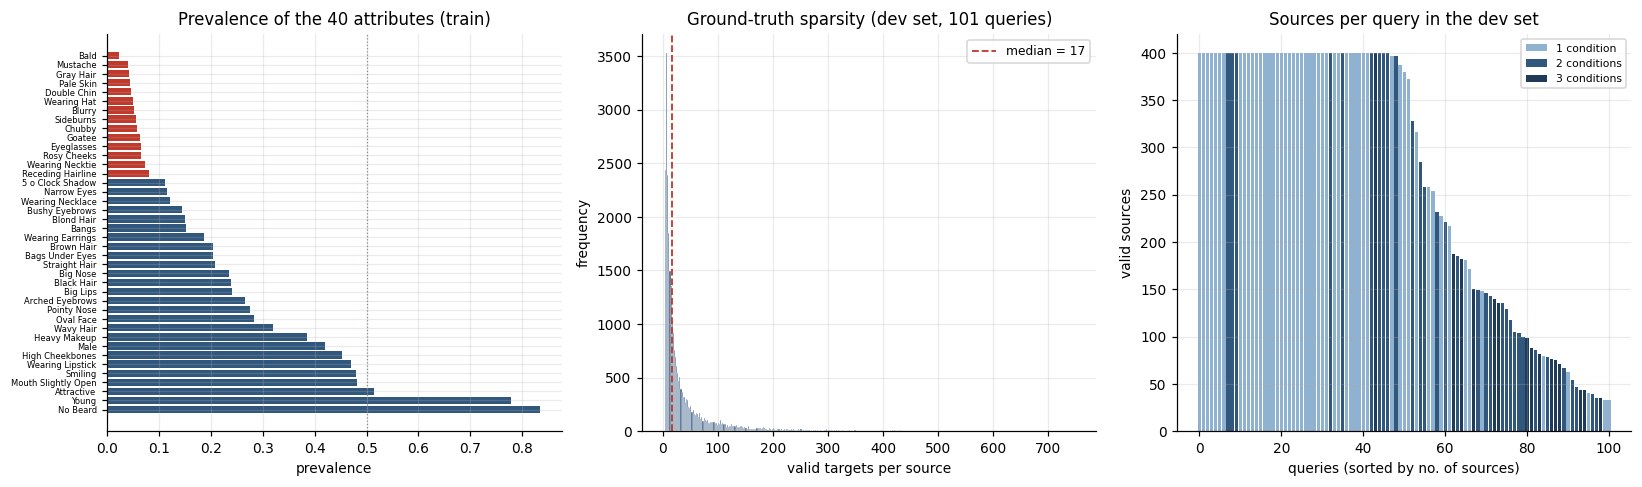


Valid targets per source: median 17, mean 40.8, range [5, 747]
Sources per query (dev): median 380, range [33, 400]
Sources per query (benchmark): median 1896, range [27, 5469]


In [6]:
# --------------------------------------------------------------- FIGURE: DATA EXPLORATION
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# --- 1. Attribute prevalence -----------------------------------------------
if HAS_TRAIN:
    prev = L_train.float().mean(0).numpy()
    split_lbl = "train"
else:
    prev = L_valid.float().mean(0).numpy()
    split_lbl = "valid"

sorted_idx = np.argsort(prev)
sorted_prev = prev[sorted_idx]
sorted_names = [attr_names[i].replace("_", " ") for i in sorted_idx]
colors = ["#c0392b" if v < 0.1 or v > 0.9 else "#31577d" for v in sorted_prev]

axes[0].barh(np.arange(len(sorted_prev)), sorted_prev, color=colors, height=0.8)
axes[0].set_yticks(np.arange(len(sorted_prev)))
axes[0].set_yticklabels(sorted_names, fontsize=5.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("prevalence")
axes[0].set_title(f"Prevalence of the 40 attributes ({split_lbl})")
axes[0].axvline(0.5, color="#7f8c8d", lw=0.8, ls=":")

# --- 2. Number of valid targets per source ---------------------------------
n_gt = []
for e in devset:
    for g in e["gt"]:
        n_gt.append(len(g))
if n_gt:
    axes[1].hist(n_gt, bins=range(0, max(n_gt) + 5, 2), color="#31577d",
                 edgecolor="white", lw=0.3)
    axes[1].axvline(np.median(n_gt), color="#c0392b", lw=1.2, ls="--",
                    label=f"median = {np.median(n_gt):.0f}")
    axes[1].legend(fontsize=8)
else:
    axes[1].text(0.5, 0.5, "no valid target", ha="center", va="center",
                 transform=axes[1].transAxes)
axes[1].set_xlabel("valid targets per source")
axes[1].set_ylabel("frequency")
axes[1].set_title(f"Ground-truth sparsity (dev set, {len(devset)} queries)")

# --- 3. Number of sources per query ----------------------------------------
n_src_dev = [len(e["sources"]) for e in devset]
n_src_test = [len(e["sources"]) for e in bench_test]
n_cond_dev = [len(e["queried"]) for e in devset]
ord_q = np.argsort([-n for n in n_src_dev])
cols_q = {1: "#8fb2d0", 2: "#31577d", 3: "#1f3b57"}
for nc in (1, 2, 3):
    mask = [i for i in ord_q if n_cond_dev[i] == nc]
    if not mask:
        continue
    x_pos = [list(ord_q).index(i) for i in mask]
    axes[2].bar(x_pos, [n_src_dev[i] for i in mask],
                color=cols_q[nc], label=f"{nc} condition{'' if nc == 1 else 's'}")
axes[2].set_xlabel("queries (sorted by no. of sources)")
axes[2].set_ylabel("valid sources")
axes[2].set_title("Sources per query in the dev set")
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.show()

print(f"\nValid targets per source: median {np.median(n_gt):.0f}, "
      f"mean {np.mean(n_gt):.1f}, range [{min(n_gt)}, {max(n_gt)}]")
print(f"Sources per query (dev): median {np.median(n_src_dev):.0f}, "
      f"range [{min(n_src_dev)}, {max(n_src_dev)}]")
print(f"Sources per query (benchmark): median {np.median(n_src_test):.0f}, "
      f"range [{min(n_src_test)}, {max(n_src_test)}]")

**Reading.** Attribute prevalence is strongly imbalanced: attributes such as `Bald` and
`Mustache` are present in fewer than 5% of the images, while `No_Beard` and `Young` exceed 80%.
This is directly reflected in the sparsity of the ground truth: the median number of valid
targets per source is low, and queries with rare attributes have fewer valid references.
Multi-condition queries, moreover, survive the "at least 5 valid targets" filter less often,
which is why the development set is sampled with fixed quotas (54/32/15% at 1/2/3 conditions) to
reproduce the composition of the benchmark.

### 1.3 The metrics

The evaluation protocol reports, at $K \in \{1,5,10\}$, averaged over all valid sources:

$$
\text{Recall@}K(v_{\text{ref}}) = \mathbb{1}\bigl[\,|\mathcal{R}_K \cap \mathcal{G}| > 0\,\bigr],
\qquad
\text{Precision@}K(v_{\text{ref}}) = \frac{|\mathcal{R}_K \cap \mathcal{G}|}{K}
$$

where $\mathcal{R}_K$ are the top $K$ retrieved images, with the reference excluded from the
ranking. Recall@K is therefore a binary **hit rate**, not the classical recall.

Aggregation is a **two-level macro-average**: first over the sources of a query, then over the
queries, so that every query weighs the same regardless of how many references it has:

$$
\overline{M} \;=\; \frac{1}{|\mathcal{Q}|}\sum_{q \in \mathcal{Q}}
\frac{1}{|\mathcal{S}_q|}\sum_{v \in \mathcal{S}_q} M(q, v)
$$

**Precision@K is computed here for the first time in the project.** It has a structural ceiling
that must be stated before reading it: the number of ground-truth items per reference is small
(the benchmark admits sources with at least 5 valid targets, but the median stays low), so
Precision@10 cannot but be far below Recall@10, and the two indices are not comparable with each
other. It serves as an index of the *density* of correct results, not as the primary metric —
which the protocol identifies as Recall@K.

---

## 2. Evaluation protocol

### 2.1 Two sets, with distinct roles

| | split | queries | references | role |
|---|---|---|---|---|
| `celeba_evaluation.json` | test | 13 distinct | 33,052 | Final yardstick. Budget **per method**, and now exhausted: spent twice, see 10.2 |
| `celeba_devset_valid.json` | valid | 101 (54/32/15) | 27,206 | Development and comparison between methods |

The development set is built with the same code that exactly reproduces the instructor's
protocol (`build_benchmark_from_labels`), on the validation split.

### 2.2 Why 13 queries are not enough

In [7]:
def reference_only(ref, entry):
    """No condition: the lower bound of the problem. No direction is needed."""
    return ref


ps_ref_test, _ = evaluate_rp(reference_only, bench_test, E_test)
ps_ref_dev,  _ = evaluate_rp(reference_only, devset, E_valid)

rows = []
for name, ps, idx in (("official benchmark", ps_ref_test, UNIQUE),
                      ("development set", ps_ref_dev, None)):
    sel = [ps[10][i] for i in (idx if idx is not None else range(len(ps[10])))]
    v = variance_decomposition(sel)
    rows.append([name, v["n_query"], f"{100 * v['macro']:.2f}%",
                  f"{100 * v['sd_between_query']:.2f}pp",
                  f"{100 * v['se_query']:.2f}pp", f"{100 * v['se_source']:.2f}pp"])
table(rows, ["", "n queries", "macro R@10", "sd between queries", "se from queries",
             "se from sources"])

sel = [ps_ref_test[10][i] for i in UNIQUE]
v = variance_decomposition(sel)
mde = 1.96 * np.sqrt(2) * v["se_query"] * 100
print(f"\nOn the benchmark, the standard error due to the queries is "
      f"{v['se_query'] / v['se_source']:.1f}x the one due to the references.")
print(f"Two UNPAIRED means over 13 queries are distinguishable only above "
      f"~{mde:.1f}pp (1.96 x sqrt(2) x se_query).")

,n queries,macro R@10,sd between queries,se from queries,se from sources
official benchmark,13,7.62%,7.38pp,2.05pp,0.43pp
development set,101,14.70%,13.74pp,1.37pp,0.22pp



On the benchmark, the standard error due to the queries is 4.8x the one due to the references.
Two UNPAIRED means over 13 queries are distinguishable only above ~5.7pp (1.96 x sqrt(2) x se_query).


All the effects at stake are below 1.5pp — well below the minimum detectable difference on 13
queries (~6.8pp). This is why every comparison is carried out on the **101 queries** of the
development set, with a paired difference and a confidence interval.

### 2.3 The tool: hierarchical paired bootstrap

Comparing two methods uses `bootstrap_paired` (20,000 resamples): the
**queries** are resampled with replacement, and within each of them the **sources**. Pairing
removes the between-query variance, which dominates the levels but cancels in the difference.

### 2.4 Honest oracles

To close a family of methods, the project measures the **ceiling** of that family: the optimal
parameter is chosen on half of the ground truth and evaluated on the other half. The difference
between a dishonest and an honest oracle is the whole story of the exclusions in sec. 6.

---

## 3. The baseline

### 3.1 Bipolar directions with template ensembling

Each attribute $a$ becomes a **bipolar direction**: the difference, averaged over $T=10$ pairs
of templates, between the prompt that asserts and the one that negates the attribute. The
baseline is

$$
\boxed{\;q \;=\; \frac{r + c}{\lVert r + c\rVert}\;}, \qquad c = \sum_{a \in T^{+}} d_a - \sum_{b \in T^{-}} d_b
$$

Prompt ensembling belongs to the baseline, not to the contribution: the baseline is built on
*"a standard, unmodified CLIP model"*, and the CLIP paper devotes a section to it
(*Prompt engineering and ensembling*, Radford et al. 2021).

In [8]:
from transformers import CLIPModel, CLIPTokenizer

TEMPLATES = [
    ("a photo of a person who is {}",        "a photo of a person who is not {}"),
    ("a photo of a person with {}",          "a photo of a person without {}"),
    ("a face with {}",                       "a face without {}"),
    ("{}",                                   "not {}"),
    ("a portrait photo of someone with {}",  "a portrait photo of someone with no {}"),
    ("a photo of a {} person",               "a photo of a person that is not {}"),
    ("a cropped photo of a face with {}",    "a cropped photo of a face without {}"),
    ("a close-up photo of a person with {}", "a close-up photo of a person without {}"),
    ("a photo of someone who has {}",        "a photo of someone who has no {}"),
    ("a picture of a face showing {}",       "a picture of a face not showing {}"),
]

clip_model = CLIPModel.from_pretrained(MODEL_ID).eval()
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID)


@torch.no_grad()
def encode(prompts):
    out = clip_model.get_text_features(**tokenizer(prompts, padding=True, return_tensors="pt"))
    f = (out.pooler_output if hasattr(out, "pooler_output") else out).float()
    return f


d_single = torch.zeros(len(attr_names), D)   # a single template: the historical defect
d_ens = torch.zeros(len(attr_names), D)      # ensembling, in the form used by CLIP
for i, name in enumerate(attr_names):
    text = name.replace("_", " ").lower()
    pos = encode([p.format(text) for p, _ in TEMPLATES])
    neg = encode([n.format(text) for _, n in TEMPLATES])
    v = pos[0] - neg[0]
    d_single[i] = v / v.norm()
    pos = pos / pos.norm(dim=-1, keepdim=True)
    neg = neg / neg.norm(dim=-1, keepdim=True)
    v = pos.mean(0) - neg.mean(0)
    d_ens[i] = v / v.norm()

del clip_model, tokenizer
print(f"{len(TEMPLATES)} template pairs x {len(attr_names)} attributes -> "
      f"{tuple(d_ens.shape)} bipolar directions")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

10 template pairs x 40 attributes -> (40, 512) bipolar directions


### 3.2 Quality of the directions

In [9]:
def auc_per_attribute(dirs, E, L):
    """AUC (Mann-Whitney) of the zero-shot classification of each attribute."""
    scores = E @ dirs.T
    out = np.full(len(attr_names), np.nan)
    for i in range(len(attr_names)):
        y = (L[:, i] == 1).numpy()
        n_pos, n_neg = int(y.sum()), int((~y).sum())
        if min(n_pos, n_neg) < 50:
            continue
        rank = np.argsort(np.argsort(scores[:, i].numpy())) + 1.0
        out[i] = (rank[y].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    return out


if HAS_TRAIN:
    SPLIT_AUC = "train"
    auc_s = auc_per_attribute(d_single, E_train, L_train)
    auc_e = auc_per_attribute(d_ens, E_train, L_train)
else:
    SPLIT_AUC = "valid (FALLBACK: train is not available)"
    auc_s = auc_per_attribute(d_single, E_valid, L_valid)
    auc_e = auc_per_attribute(d_ens, E_valid, L_valid)

print(f"AUC computed on split: {SPLIT_AUC}")
print(f"mean AUC over the 40 attributes   single template {np.nanmean(auc_s):.3f}   "
      f"ensembling {np.nanmean(auc_e):.3f}")
print(f"attributes with an INVERTED direction (AUC < 0.5): "
      f"{int(np.nansum(auc_s < 0.5))} -> {int(np.nansum(auc_e < 0.5))}")
print(f"\n{'attribute':<22}{'single':>9}{'ensemble':>10}")
for i in np.argsort(auc_s)[:6]:
    print(f"{attr_names[i]:<22}{auc_s[i]:>9.3f}{auc_e[i]:>10.3f}")

AUC computed on split: train
mean AUC over the 40 attributes   single template 0.649   ensembling 0.691
attributes with an INVERTED direction (AUC < 0.5): 9 -> 7

attribute                single  ensemble
Sideburns                 0.316     0.495
Rosy_Cheeks               0.414     0.488
5_o_Clock_Shadow          0.418     0.447
Wearing_Necklace          0.418     0.481
Oval_Face                 0.440     0.497
Attractive                0.464     0.561


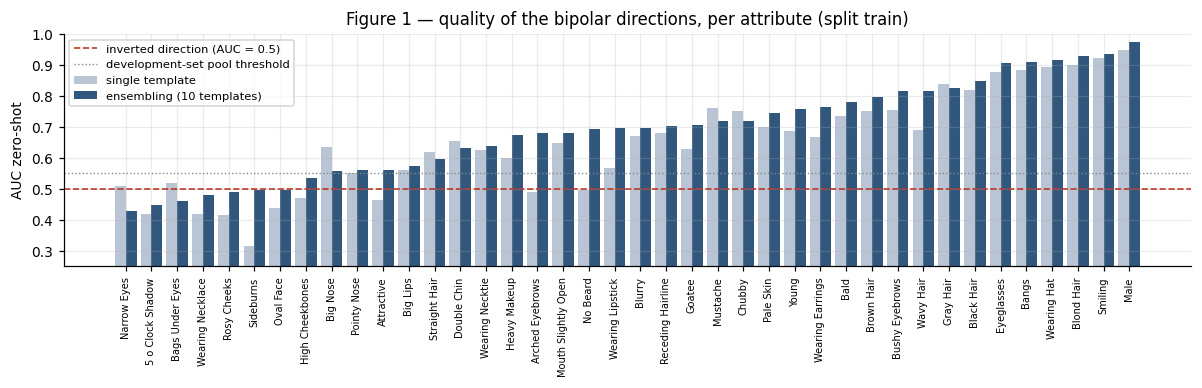

In [10]:
SPLIT_AUC = globals().get("SPLIT_AUC")
# ---------------------------------------------------------------- FIGURE 1
order = np.argsort(auc_e)
x = np.arange(len(attr_names))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(x - 0.21, auc_s[order], width=0.42, label="single template", color="#b9c4d4")
ax.bar(x + 0.21, auc_e[order], width=0.42, label="ensembling (10 templates)", color="#31577d")
ax.axhline(0.5, color="#c0392b", lw=1.1, ls="--", label="inverted direction (AUC = 0.5)")
ax.axhline(0.55, color="#7f8c8d", lw=0.9, ls=":", label="development-set pool threshold")
ax.set_xticks(x)
ax.set_xticklabels([attr_names[i].replace("_", " ") for i in order], rotation=90, fontsize=6.5)
ax.set_ylim(0.25, 1.0)
ax.set_ylabel("AUC zero-shot")
ax.set_title(f"Figure 1 — quality of the bipolar directions, per attribute (split {SPLIT_AUC})")
ax.legend(fontsize=7.5, loc="upper left")
plt.tight_layout()
plt.show()

With a single template, **nine attributes out of forty have their direction inverted** with
respect to the label. Ensembling recovers two of them; seven remain. On those conditions no
fusion module can work: the signal is not there upstream.

### 3.3 Baseline result

In [11]:
def build_baseline(dirs, alpha=1.0, normalise_c=False):
    """q = normalize(r + alpha * c), with c the SIGNED sum of the directions.

    `normalise_c=False` is the baseline formula: the sum must NOT be normalised.
    The vector c depends only on the query, so it is computed once and reused.
    """
    cache = {}

    def build(ref, entry):
        key = entry["query"]
        if key not in cache:
            c = torch.zeros(D)
            for i in entry["pos"]:
                c = c + dirs[i]
            for j in entry["neg"]:
                c = c - dirs[j]
            cache[key] = c / c.norm().clamp(min=1e-8) if normalise_c else c
        q = ref + alpha * cache[key]
        return q / q.norm(dim=-1, keepdim=True)

    return build


BASE_METHODS = {
    "reference only (lower bound)": reference_only,
    "baseline, single template":   build_baseline(d_single),
    "baseline, with ensembling":   build_baseline(d_ens),
    "baseline, normalised sum":    build_baseline(d_ens, normalise_c=True),
}

R_test, P_test, R_dev, P_dev = {}, {}, {}, {}
for name, fn in BASE_METHODS.items():
    R_test[name], P_test[name] = evaluate_rp(fn, bench_test, E_test)
    R_dev[name],  P_dev[name]  = evaluate_rp(fn, devset, E_valid)


def rp_table(R, P, names, indices=None, title=""):
    columns = ["method"] + [f"R@{k}" for k in K_VALUES] + [f"P@{k}" for k in K_VALUES]
    rows = []
    for name in names:
        r, p = macro_on(R[name], indices), macro_on(P[name], indices)
        rows.append([name] + [f"{100 * r[k]:.2f}%" for k in K_VALUES]
                           + [f"{100 * p[k]:.2f}%" for k in K_VALUES])
    table(rows, columns, title)


rp_table(R_test, P_test, BASE_METHODS, UNIQUE,
         "OFFICIAL BENCHMARK — 13 distinct queries, macro-average")
rp_table(R_dev, P_dev, BASE_METHODS, None,
         "DEVELOPMENT SET — 101 queries, macro-average")

method,R@1,R@5,R@10,P@1,P@5,P@10
reference only (lower bound),1.73%,5.29%,7.62%,1.73%,1.31%,1.09%
"baseline, single template",3.31%,8.87%,13.39%,3.31%,2.18%,1.86%
"baseline, with ensembling",3.90%,10.99%,15.92%,3.90%,2.73%,2.20%
"baseline, normalised sum",3.39%,9.75%,14.67%,3.39%,2.40%,2.02%


method,R@1,R@5,R@10,P@1,P@5,P@10
reference only (lower bound),3.23%,10.14%,14.70%,3.23%,2.76%,2.37%
"baseline, single template",3.97%,12.46%,18.49%,3.97%,3.26%,2.87%
"baseline, with ensembling",4.22%,13.34%,19.91%,4.22%,3.49%,3.06%
"baseline, normalised sum",4.09%,12.95%,19.09%,4.09%,3.40%,2.97%


In [12]:
def compare(R, a, b, label, indices=None, n_boot=20000):
    """Paired difference A - B with hierarchical bootstrap, at every K."""
    print(f"{label}\n   ({a}  against  {b})")
    for k in K_VALUES:
        ra = [R[a][k][i] for i in indices] if indices is not None else R[a][k]
        rb = [R[b][k][i] for i in indices] if indices is not None else R[b][k]
        s = bootstrap_paired(ra, rb, n_boot=n_boot, seed=0)
        star = "  significant" if s["p"] < 0.05 else ""
        print(f"    R@{k:<3}{100 * s['delta']:>+7.2f}pp   CI [{100 * s['lo']:+.2f}, "
              f"{100 * s['hi']:+.2f}]   p = {s['p']:.4f}   "
              f"({s['n_query_win']} queries won / {s['n_query_loss']} lost){star}")
    print()


compare(R_test, "baseline, with ensembling", "baseline, single template",
        "BENCHMARK — what using CLIP properly is worth", UNIQUE)
compare(R_dev, "baseline, with ensembling", "baseline, single template",
        "DEVELOPMENT — what using CLIP properly is worth")
compare(R_dev, "baseline, with ensembling", "baseline, normalised sum",
        "DEVELOPMENT — what normalising the sum of the directions was costing")
compare(R_test, "baseline, with ensembling", "reference only (lower bound)",
        "BENCHMARK — what the conditioning is worth in itself", UNIQUE)

# --- the variance decomposition of sec. 2.2, now on the BASELINE -----------------------
rows = []
for name, R, idx in (("official benchmark", R_test, UNIQUE),
                     ("development set", R_dev, None)):
    ps = R["baseline, with ensembling"][10]
    sel = [ps[i] for i in (idx if idx is not None else range(len(ps)))]
    v = variance_decomposition(sel)
    rows.append([name, v["n_query"], f"{100 * v['macro']:.2f}%",
                 f"{100 * v['sd_between_query']:.2f}pp", f"{100 * v['se_query']:.2f}pp",
                 f"{100 * v['se_source']:.2f}pp",
                 f"{1.96 * np.sqrt(2) * v['se_query'] * 100:.2f}pp"])
table(rows, ["", "n queries", "macro R@10", "sd between queries", "se from queries",
             "se from sources", "min. detectable"],
      "Uncertainty decomposition of the macro-average, on the baseline with ensembling")

BENCHMARK — what using CLIP properly is worth
   (baseline, with ensembling  against  baseline, single template)
    R@1    +0.59pp   CI [-0.52, +1.61]   p = 0.2490   (9 queries won / 3 lost)
    R@5    +2.12pp   CI [+0.94, +3.50]   p = 0.0000   (11 queries won / 0 lost)  significant


    R@10   +2.53pp   CI [+1.08, +4.27]   p = 0.0000   (10 queries won / 1 lost)  significant

DEVELOPMENT — what using CLIP properly is worth
   (baseline, with ensembling  against  baseline, single template)


    R@1    +0.24pp   CI [-0.06, +0.54]   p = 0.1128   (45 queries won / 29 lost)


    R@5    +0.88pp   CI [+0.29, +1.49]   p = 0.0018   (56 queries won / 31 lost)  significant


    R@10   +1.42pp   CI [+0.75, +2.14]   p = 0.0000   (61 queries won / 29 lost)  significant

DEVELOPMENT — what normalising the sum of the directions was costing
   (baseline, with ensembling  against  baseline, normalised sum)


    R@1    +0.12pp   CI [-0.03, +0.30]   p = 0.1245   (15 queries won / 8 lost)


    R@5    +0.38pp   CI [-0.04, +0.87]   p = 0.0775   (18 queries won / 13 lost)


    R@10   +0.83pp   CI [+0.30, +1.45]   p = 0.0003   (24 queries won / 10 lost)  significant

BENCHMARK — what the conditioning is worth in itself
   (baseline, with ensembling  against  reference only (lower bound))
    R@1    +2.16pp   CI [+0.47, +4.12]   p = 0.0122   (11 queries won / 1 lost)  significant
    R@5    +5.70pp   CI [+2.25, +9.33]   p = 0.0012   (11 queries won / 1 lost)  significant


    R@10   +8.30pp   CI [+3.62, +13.26]   p = 0.0003   (11 queries won / 1 lost)  significant



,n queries,macro R@10,sd between queries,se from queries,se from sources,min. detectable
official benchmark,13,15.92%,9.87pp,2.74pp,0.52pp,7.59pp
development set,101,19.91%,12.80pp,1.27pp,0.28pp,3.53pp


**The baseline is worth 15.92% Recall@10 on the benchmark and 19.91% on the development set.**
Prompt ensembling is worth +2.53pp (p < 0.001), and the correct formula (unnormalised sum)
another point. Together, the two defects were underestimating the baseline by more than three
points.

The comparison with the reference alone (7.62%) gives the measure of the margin: **all of the
conditioning is worth the difference between those two rows**, and it is inside that margin that
every method has to find room.

---

## 4. The contribution: a learned projection head

### 4.1 The idea

Instead of adding the textual direction directly, a module $\Phi$ reads the pair
**(reference, conditions)** and produces a 512-dimensional **displacement vector**:

$$
\text{baseline:}\quad q = \frac{r + c}{\lVert r + c\rVert}
\qquad\longrightarrow\qquad
\text{contribution:}\quad q = \frac{r + \gamma\,\Phi([r\,;\,c])}{\lVert r + \gamma\,\Phi([r\,;\,c])\rVert}
$$

CLIP stays frozen, the database untouched, the ranking stays a dot product: **the inference cost
is identical to the baseline.**

**Where this section ends up.** The module below is the *instrument*, not the deliverable.
Once it worked we did not know what it computed, and characterising it (sec. 5) ended up
changing what we ship: the delivered method is a **single matrix**, obtained by collapsing the
module. Sec. 4.9 is the chain of measurements that leads from one to the other, and the
intermediate steps are worth reading because each of them is a result on its own.


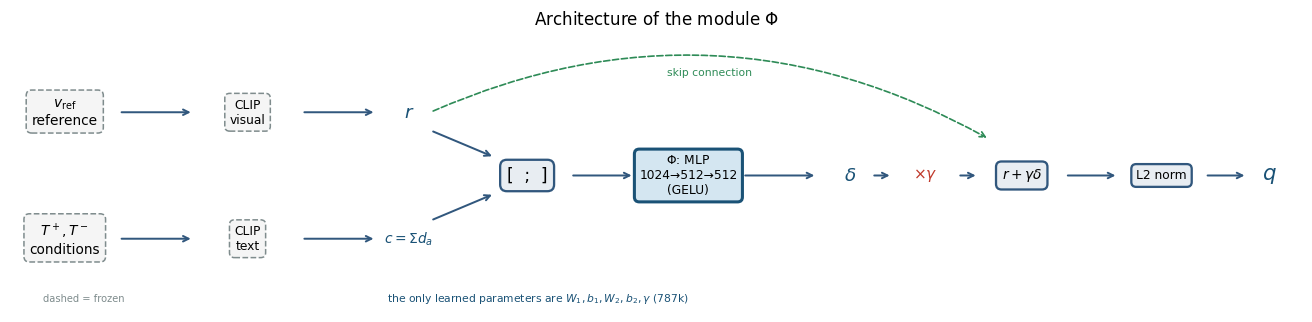

In [13]:
# -------------------------------------------------------------- FIGURE: ARCHITECTURE DIAGRAM
fig, ax = plt.subplots(figsize=(12, 3))
ax.set_xlim(0, 12)
ax.set_ylim(0, 3)
ax.axis("off")

box_style = dict(boxstyle="round,pad=0.4", facecolor="#e8edf2", edgecolor="#31577d", lw=1.5)
box_highlight = dict(boxstyle="round,pad=0.4", facecolor="#d4e6f1", edgecolor="#1a5276", lw=2)
box_frozen = dict(boxstyle="round,pad=0.4", facecolor="#f5f5f5", edgecolor="#7f8c8d", lw=1, ls="--")

# Input blocks
ax.text(0.5, 2.2, "$v_{\\mathrm{ref}}$\nreference", ha="center", va="center", fontsize=9,
        bbox=box_frozen)
ax.text(0.5, 0.8, "$T^+, T^-$\nconditions", ha="center", va="center", fontsize=9,
        bbox=box_frozen)

# CLIP encoders
ax.text(2.2, 2.2, "CLIP\nvisual", ha="center", va="center", fontsize=8, bbox=box_frozen)
ax.text(2.2, 0.8, "CLIP\ntext", ha="center", va="center", fontsize=8, bbox=box_frozen)

# r and c
ax.text(3.7, 2.2, "$r$", ha="center", va="center", fontsize=12, color="#1a5276")
ax.text(3.7, 0.8, r"$c = \Sigma d_a$", ha="center", va="center", fontsize=9, color="#1a5276")

# Concat
ax.text(4.8, 1.5, "[  ;  ]", ha="center", va="center", fontsize=11, bbox=box_style)

# MLP
ax.text(6.3, 1.5, "$\\Phi$: MLP\n1024→512→512\n(GELU)", ha="center", va="center",
        fontsize=8, bbox=box_highlight)

# delta
ax.text(7.8, 1.5, r"$\delta$", ha="center", va="center", fontsize=12, color="#1a5276")

# gamma
ax.text(8.5, 1.5, r"$\times\gamma$", ha="center", va="center", fontsize=10, color="#c0392b")

# sum with r
ax.text(9.4, 1.5, r"$r + \gamma\delta$", ha="center", va="center", fontsize=9, bbox=box_style)

# normalize
ax.text(10.7, 1.5, "L2 norm", ha="center", va="center", fontsize=8, bbox=box_style)

# output
ax.text(11.7, 1.5, "$q$", ha="center", va="center", fontsize=14, fontweight="bold",
        color="#1a5276")

# Arrows
arrow = dict(arrowstyle="->", color="#31577d", lw=1.3)
for (x1,y1,x2,y2) in [(1.0,2.2,1.7,2.2), (1.0,0.8,1.7,0.8),  # inputs -> CLIP
                        (2.7,2.2,3.4,2.2), (2.7,0.8,3.4,0.8),  # CLIP -> r,c
                        (3.9,2.0,4.5,1.7), (3.9,1.0,4.5,1.3),  # r,c -> concat
                        (5.2,1.5,5.8,1.5),                       # concat -> MLP
                        (6.8,1.5,7.5,1.5),                       # MLP -> delta
                        (8.0,1.5,8.2,1.5),                       # delta -> gamma
                        (8.8,1.5,9.0,1.5),                       # gamma -> sum
                        (9.8,1.5,10.3,1.5),                      # sum -> norm
                        (11.1,1.5,11.5,1.5)]:                    # norm -> q
    ax.annotate("", xy=(x2,y2), xytext=(x1,y1), arrowprops=arrow)

# r skip connection
ax.annotate("", xy=(9.1, 1.9), xytext=(3.9, 2.2),
            arrowprops=dict(arrowstyle="->", color="#2e8b57", lw=1.1, ls="--",
                            connectionstyle="arc3,rad=-0.25"))
ax.text(6.5, 2.6, "skip connection", fontsize=7, color="#2e8b57", ha="center")

# Legend
ax.text(0.3, 0.1, "dashed = frozen", fontsize=6.5, color="#7f8c8d")
ax.text(3.5, 0.1, r"the only learned parameters are $W_1, b_1, W_2, b_2, \gamma$ (787k)", fontsize=7, color="#1a5276")

ax.set_title(r"Architecture of the module $\Phi$", fontsize=11, pad=10)
plt.tight_layout()
plt.show()

### 4.2 Forward pass

$$
\Phi([r\,;\,c]) \;=\; W_2\,\sigma\bigl(W_1 [r\,;\,c] + b_1\bigr) + b_2,
\qquad
W_1 \in \mathbb{R}^{512 \times 1024},\; W_2 \in \mathbb{R}^{512 \times 512}
$$

with $\sigma$ = GELU. $W_2, b_2$ are initialised to **zero**: at startup $\delta = 0$ and
$q = r$, so the model starts from the pure identity.

The module belongs to the family of *non-linear projection heads*. The difference with respect to the earlier attempt, which produced **scalars**, is
that here the output is a **vector** — one that can point outside $\operatorname{span}(r, c)$,
where the oracles had shown there is no margin.

### 4.3 Loss: multi-positive InfoNCE

Training uses an InfoNCE with the denominator over the whole corpus (20,000 images) and
**several positives per query**: the ground truth are the targets that satisfy the conditions
*and* lie within Hamming ≤ 2 of the reference — the benchmark's own rule, built by the same code
that replicates the official protocol.

In [14]:
import torch.nn as nn

HIDDEN, N_HEADS = 512, 4
TAU = 0.03                      # temperature, chosen in the original run on held-out queries
BATCH, LR, WD = 256, 3e-4, 1e-4
EPOCHS = 30                     # fixed A PRIORI, not chosen by looking at the development set
N_CORPUS = 20000
QUERY_TARGET = {1: 80, 2: 80, 3: 60}
MAX_SOURCES = 80


class Concat(nn.Module):
    """The contribution: q = normalize(r + gamma * MLP([r ; c])).

    The conditions arrive as a tensor U [B, 3, D] with a mask M [B, 3] (up to three per query,
    already signed: +d for T+, -d for T-) and are SUMMED before the MLP.
    The last layer is initialised to zero: at startup q = r exactly.
    """

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * D, HIDDEN), nn.GELU(), nn.Linear(HIDDEN, D))
        self.gamma = nn.Parameter(torch.tensor(1.0))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, r, U, M):
        c = (U * M.unsqueeze(-1)).sum(1)
        delta = self.net(torch.cat([r, c], dim=-1))
        q = r + self.gamma * delta
        return q / q.norm(dim=-1, keepdim=True).clamp(min=1e-8), delta


class CrossAttn(nn.Module):
    """The controlled comparison: the reference acts as the query, the conditions as key/value.

    Same downstream capacity, same loss, same data. It is one of the four avenues the
    literature suggests, and the natural alternative to concatenation.
    """

    def __init__(self):
        super().__init__()
        self.attn = nn.MultiheadAttention(D, N_HEADS, batch_first=True)
        self.net = nn.Sequential(nn.Linear(2 * D, HIDDEN), nn.GELU(), nn.Linear(HIDDEN, D))
        self.gamma = nn.Parameter(torch.tensor(1.0))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, r, U, M):
        ctx, _ = self.attn(r.unsqueeze(1), U, U, key_padding_mask=~M, need_weights=False)
        delta = self.net(torch.cat([r, ctx.squeeze(1)], dim=-1))
        q = r + self.gamma * delta
        return q / q.norm(dim=-1, keepdim=True).clamp(min=1e-8), delta


def info_nce_multipos(q, E_corpus, refs, gts, tau=TAU):
    """Multi-positive InfoNCE, denominator over the WHOLE corpus, reference excluded.

    Returns (loss, chance_level). The chance level is log((N-1)/|G_i|) averaged over the
    batch: it is the value the loss would take with uniform scores, and it lets one read the
    gap instead of the absolute value (which depends on how many positives each example has).
    """
    sim = (q @ E_corpus.T) / tau
    B, N = sim.shape
    ar = torch.arange(B)
    sim = sim.clone()
    sim[ar, refs] = -float("inf")                      # the reference is not a target
    pos = torch.zeros(B, N, dtype=torch.bool)
    for i, gt in enumerate(gts):
        pos[i, gt] = True
    pos[ar, refs] = False
    num = torch.logsumexp(sim.masked_fill(~pos, -float("inf")), dim=1)
    den = torch.logsumexp(sim, dim=1)
    n_pos = pos.sum(1).float().clamp(min=1)
    return -(num - den).mean(), torch.log((N - 1) / n_pos).mean().item()


# --- loss sanity check: with a SINGLE positive it must reduce to the standard InfoNCE ------
_g = torch.Generator().manual_seed(0)
_q = torch.randn(4, D, generator=_g)
_q = _q / _q.norm(dim=-1, keepdim=True)
_E = torch.randn(50, D, generator=_g)
_E = _E / _E.norm(dim=-1, keepdim=True)
_refs = torch.tensor([0, 1, 2, 3])
_gts = [torch.tensor([10]), torch.tensor([11]), torch.tensor([12]), torch.tensor([13])]
_l, _ = info_nce_multipos(_q, _E, _refs, _gts)
_sim = (_q @ _E.T) / TAU
_sim[torch.arange(4), _refs] = -float("inf")
_expected = nn.functional.cross_entropy(_sim, torch.tensor([10, 11, 12, 13]))
print(f"loss check (1 positive): {_l.item():.6f} against cross_entropy "
      f"{_expected.item():.6f}  ->  {'they match' if abs(_l - _expected) < 1e-5 else 'DIFFERENT'}")

loss check (1 positive): 6.536306 against cross_entropy 6.536306  ->  they match


### 4.4 Experimental setup

Capacity, optimiser, hyperparameters and data sampling are motivated below.

**Capacity — deliberately small.** Two layers, 787k parameters, on 4,407 examples. The
unfavourable ratio was put to the test: adding a LayerNorm raises the fit to 99.39% and lowers
the dev to 18.53%, **below the baseline** (−8.73pp, p < 0.0001). More capacity makes it worse.

**Optimiser — AdamW** (lr = 3·10⁻⁴, weight decay = 10⁻⁴, batch 256). AdamW is the natural choice
for a lightweight module attached to a frozen encoder: the adaptive moments handle the different
scales between $r$ (normalised) and $c$ (not normalised) without requiring a per-component
learning-rate tuning. The weight decay contributes to the regularisation that keeps the map
almost linear (sec. 5.1) — consistent with the observation that forcing non-linearity makes
things worse. A batch size of 256 over ~4,400 examples gives ~17 batches per epoch: enough for
stable gradient estimates, few enough to converge in 30 epochs.

**Temperature $\tau$ = 0.03**, chosen in the original run on held-out training queries and never
touched afterwards. It is the only hyperparameter selected through a procedure, and the value is
consistent with the scale of the cosines in CLIP space (where similarities typically fall in
[0.15, 0.35]).

**Epochs: 30, fixed a priori.** Not chosen by looking at the development set. On the large
configurations (sec. 5.4), where the stopping point matters, an honest validation on fresh
queries is used.

**Sampling of the training queries:** 80 queries with 1 condition, 80 with 2, 60 with 3. The
proportions tilt the composition of the benchmark (which is ~54/31/15%) towards composed
queries, which are more informative: every 2-condition example contributes to two attribute
directions, and the Hamming constraints are tighter. The parameter `max_sources` = 80 limits the
references per query in the training set; sec. 5.4 shows that this was the main bottleneck.

### 4.5 Training and result

In [15]:
if not HAS_TRAIN:
    print("SKIPPED: the embeddings of the train split are not available.\n"
          "The reference numbers remain those of the recorded result files.")
else:
    t0 = time.time()
    g = torch.Generator().manual_seed(SEED)
    sub = torch.randperm(len(E_train), generator=g)[:N_CORPUS].sort().values
    E_tr, L_tr = E_train[sub], L_train[sub]

    query_txt = []
    for n_cond, how_many in QUERY_TARGET.items():
        query_txt += sample_queries(list(attr_names), how_many, n_cond,
                                    exclude=query_txt, seed=SEED + n_cond)

    train_bench = []
    for qt in query_txt:
        train_bench += build_benchmark_from_labels([qt], L_tr, attr_names,
                                                   max_sources=MAX_SOURCES, seed=SEED)

    # subset of the training queries used for tracking during training:
    # it is NOT the development set, and it is not used to choose anything
    gg = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(train_bench), generator=gg).tolist()
    BENCH_TRACK = [train_bench[i] for i in perm[:int(0.20 * len(train_bench))]]

    def condition_tensor(entry, max_n=3):
        u = torch.zeros(max_n, D)
        m = torch.zeros(max_n, dtype=torch.bool)
        k = 0
        for a in entry["pos"][:max_n]:
            u[k], m[k] = d_ens[a], True
            k += 1
        for b in entry["neg"][:max_n - k]:
            u[k], m[k] = -d_ens[b], True
            k += 1
        return u, m

    EXAMPLES = []
    for e in train_bench:
        u, m = condition_tensor(e)
        for si, ref in enumerate(e["sources"].tolist()):
            EXAMPLES.append((ref, u, m, torch.tensor(sorted(e["gt"][si]), dtype=torch.long)))

    n_seen = sum(1 for e in devset if e["query"] in {x["query"] for x in train_bench})
    comp_dev = {n: [e for e in devset if len(e["queried"]) == n] for n in (1, 2, 3)}
    seen_per_n = {n: sum(1 for e in v if e["query"] in {x["query"] for x in train_bench})
                  for n, v in comp_dev.items()}

    print(f"training corpus          : {N_CORPUS} images from the train split")
    print(f"sampled queries          : {len(query_txt)}, of which {len(train_bench)} with at "
          f"least one valid reference")
    print(f"examples (reference, query): {len(EXAMPLES)}")
    print(f"module parameters        : {sum(p.numel() for p in Concat().parameters()):,}")
    print(f"\nDevelopment-set queries already seen in training: {n_seen}/{len(devset)}")
    for n in (1, 2, 3):
        print(f"   with {n} condition{'' if n == 1 else 's'}: "
              f"{seen_per_n[n]}/{len(comp_dev[n])} seen")
    print(f"\n({time.time() - t0:.0f}s)")

training corpus          : 20000 images from the train split
sampled queries          : 220, of which 182 with at least one valid reference
examples (reference, query): 4407
module parameters        : 787,457

Development-set queries already seen in training: 55/101
   with 1 condition: 54/54 seen
   with 2 conditions: 1/32 seen
   with 3 conditions: 0/15 seen

(11s)


**This table is the premise without which the result would not be interpretable.** The
one-condition queries are *all* seen, and it could not have been otherwise: with 40 attributes
and two signs there are only 80 of them, and training uses all of them. But **almost all the
composed queries of the development set are combinations the model has never seen**. If the gain
were a lookup on known queries, it should concentrate on the simple ones; sec. 4.8 shows the
opposite happens.

### 4.6 Why the training ground truth follows the benchmark's own rule

This is the main reason the method works where everything else failed, and it is worth isolating.

The training positives are, **by construction**, the images that satisfy the conditions *and*
lie within Hamming ≤ 2 of the reference — that is, the rule of the provided ground truth,
literally, generated by the same code that replicates the official protocol. The model therefore
learns to move in ways that satisfy the condition **without breaking the identity**.

The textual direction $d_a$ does not even know an identity constraint exists: it only knows
semantics. The oracle ceiling of sec. 6.4 says that the second of the two jobs $c$ performs is
pure cost: here that cost is **optimised away**, instead of being suffered.

In [16]:
BENCH_TRACK = globals().get("BENCH_TRACK")
EXAMPLES = globals().get("EXAMPLES")
def builder(model):
    """Adapts a trained module to the `build_query(ref_embs, entry) -> [n, D]` interface
    used by `evaluate_query` above."""
    cache = {}

    def f(ref, entry):
        key = entry["query"]
        if key not in cache:
            cache[key] = condition_tensor(entry)
        u, m = cache[key]
        with torch.no_grad():
            q, _ = model(ref, u.unsqueeze(0).expand(len(ref), -1, -1),
                         m.unsqueeze(0).expand(len(ref), -1))
        return q

    return f


def train(make_model, examples, E_corpus, name, epochs=EPOCHS, every=5, track_dev=False):
    torch.manual_seed(SEED)
    model = make_model()
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    gen = torch.Generator().manual_seed(SEED)
    history = []
    print(f"--- {name}: tau={TAU}, {epochs} epochs, {len(examples)} examples, "
          f"batch {BATCH}, AdamW(lr={LR}, wd={WD}) ---", flush=True)
    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(examples), generator=gen)
        tot_l = tot_c = 0.0
        nb = 0
        for st in range(0, len(examples), BATCH):
            idx = order[st:st + BATCH].tolist()
            refs = torch.tensor([examples[i][0] for i in idx])
            U = torch.stack([examples[i][1] for i in idx])
            M = torch.stack([examples[i][2] for i in idx])
            gts = [examples[i][3] for i in idx]
            q, _ = model(E_corpus[refs], U, M)
            loss, chance = info_nce_multipos(q, E_corpus, refs, gts)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot_l += loss.item()
            tot_c += chance
            nb += 1
        row = {"epoch": ep + 1, "loss": tot_l / nb, "chance": tot_c / nb,
               "gamma": float(model.gamma.detach())}
        if (ep + 1) % every == 0 or ep == epochs - 1:
            model.eval()
            row["r10_fit"] = macro(evaluate_per_source(builder(model), BENCH_TRACK,
                                                       E_corpus, [10])[10]) * 100
            if track_dev:
                row["r10_dev"] = macro(evaluate_per_source(builder(model), devset,
                                                          E_valid, [10])[10]) * 100
            extra = f"   R@10 fit {row['r10_fit']:5.2f}%"
            if track_dev:
                extra += f"   R@10 dev {row['r10_dev']:5.2f}%"
            print(f"  epoch {ep + 1:>3}   loss {row['loss']:6.3f}   chance {row['chance']:6.3f}"
                  f"   gap {row['chance'] - row['loss']:6.3f}   gamma {row['gamma']:5.3f}"
                  f"{extra}   ({time.time() - T_START:.0f}s)", flush=True)
        history.append(row)
    model.eval()
    return model, history


# ---------------------------------------------------------------------- LOAD, OR TRAIN
# The module is deterministic given the seed, so it is stored once and loaded here rather than
# retrained on every run: the sections that analyse it (5.1, 5.2, 8.6) need the module itself,
# not a number copied from a file. Sec. 11.2 retrains it from scratch and overwrites what is
# loaded here — the check that the two agree is that both give 27.26% on the development set.
CKPT_DIR = ROOT / "contributo-candidato/checkpoints"
CKPT = CKPT_DIR / "models_seed2026.pt"
HIST_FILE = CKPT_DIR / "storia_seed2026.json"
TRAIN_B = True     # the controlled comparison with cross-attention; ~40 s extra
RETRAIN = False    # set to True  (or run sec. 11.2) to train from scratch instead of loading


def salva(mod_a, mod_b, hist_a, hist_b):
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    json.dump({"A": hist_a, "B": hist_b}, open(HIST_FILE, "w"))
    if CKPT.exists():
        # the stored module is what the rest of the report was measured on: a retraining run
        # writes its history, but does not silently replace it. Delete the file to replace it.
        print(f"   ({CKPT.name} already exists and was not overwritten)")
        return
    torch.save({"A": mod_a.state_dict(),
                "B": mod_b.state_dict() if mod_b is not None else None,
                "seed": SEED, "tau": {"A": TAU, "B": TAU},
                "config": {"hidden": HIDDEN, "n_heads": N_HEADS, "d": D, "n_attr": len(attr_names)},
                "dirs_text": d_ens, "attr_names": attr_names}, CKPT)


def carica():
    """The stored module, or None if it is not among the materials."""
    if not CKPT.exists():
        return None
    st = torch.load(CKPT, map_location="cpu", weights_only=False)
    a = Concat()
    a.load_state_dict(st["A"])
    a.eval()
    b = None
    if st.get("B") is not None:
        b = CrossAttn()
        b.load_state_dict(st["B"])
        b.eval()
    ha = hb = None
    if HIST_FILE.exists():
        h = json.load(open(HIST_FILE))
        ha, hb = h.get("A"), h.get("B")
    return a, b, ha, hb


stored = None if RETRAIN else carica()
if stored is not None:
    MOD_A, MOD_B, HIST_A, HIST_B = stored
    print(f"module loaded from {CKPT.name} (seed {SEED}); sec. 11.2 retrains it from scratch")
    if HIST_A is None:
        print("   (the training history is not stored: the learning curves below are skipped)")
elif HAS_TRAIN:
    MOD_A, HIST_A = train(Concat, EXAMPLES, E_tr, "A: concatenation", track_dev=True)
    MOD_B, HIST_B = (train(CrossAttn, EXAMPLES, E_tr, "B: cross-attention")
                     if TRAIN_B else (None, None))
    salva(MOD_A, MOD_B, HIST_A, HIST_B)
    print(f"trained from scratch and stored in {CKPT.name}")
else:
    MOD_A = MOD_B = HIST_A = HIST_B = None
    print("SKIPPED: neither the stored module nor the train-split embeddings are available.")

module loaded from models_seed2026.pt (seed 2026); sec. 11.2 retrains it from scratch


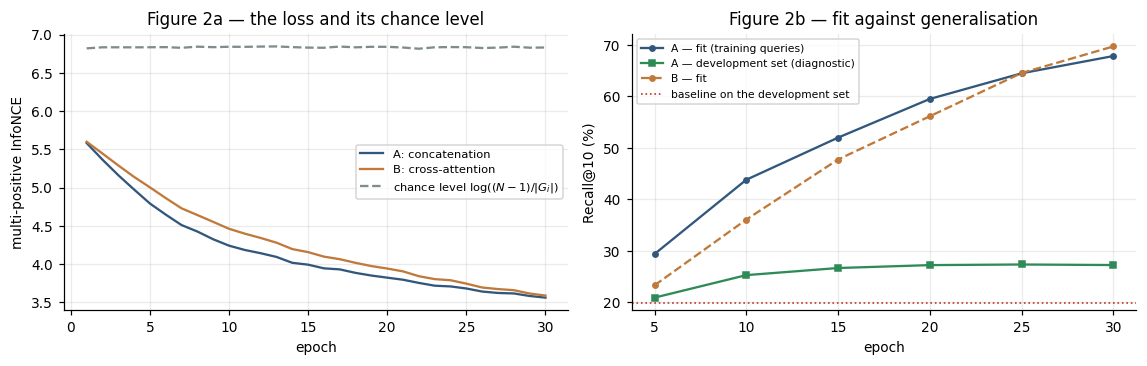

fit/dev gap at the end: 67.8% against 27.3%  ->  the module memorises far more than it transfers:
it is not a capacity problem (adding capacity makes it worse), it is a problem of the number of examples.


In [17]:
# sec. 4.5 may not have been run: the absence is tolerated instead of failing with a
# NameError, so the notebook holds up even when executed cell by cell
HIST_A = globals().get("HIST_A")
HIST_B = globals().get("HIST_B")

# --------------------------------------------------------------- FIGURE 2 (learning curve)
if HIST_A is not None:
    ep = [r["epoch"] for r in HIST_A]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.4))

    a1.plot(ep, [r["loss"] for r in HIST_A], color="#31577d", label="A: concatenation")
    if HIST_B is not None:
        a1.plot(ep, [r["loss"] for r in HIST_B], color="#c0793a", label="B: cross-attention")
    a1.plot(ep, [r["chance"] for r in HIST_A], color="#7f8c8d", ls="--",
            label=r"chance level $\log((N-1)/|G_i|)$")
    a1.set_xlabel("epoch")
    a1.set_ylabel("multi-positive InfoNCE")
    a1.set_title("Figure 2a — the loss and its chance level")
    a1.legend(fontsize=7.5)

    tr = [r for r in HIST_A if "r10_fit" in r]
    a2.plot([r["epoch"] for r in tr], [r["r10_fit"] for r in tr], "o-", ms=3.5,
            color="#31577d", label="A — fit (training queries)")
    a2.plot([r["epoch"] for r in tr], [r["r10_dev"] for r in tr], "s-", ms=3.5,
            color="#2e8b57", label="A — development set (diagnostic)")
    if HIST_B is not None:
        tb = [r for r in HIST_B if "r10_fit" in r]
        a2.plot([r["epoch"] for r in tb], [r["r10_fit"] for r in tb], "o--", ms=3.5,
                color="#c0793a", label="B — fit")
    a2.axhline(19.91, color="#c0392b", lw=1.1, ls=":", label="baseline on the development set")
    a2.set_xlabel("epoch")
    a2.set_ylabel("Recall@10 (%)")
    a2.set_title("Figure 2b — fit against generalisation")
    a2.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

    print(f"fit/dev gap at the end: {tr[-1]['r10_fit']:.1f}% against "
          f"{tr[-1]['r10_dev']:.1f}%  ->  the module memorises far more than it "
          f"transfers:\nit is not a capacity problem (adding capacity makes it worse), it is a "
          f"problem of the number of examples.")

In [18]:
# sec. 4.5 may not have been run: the absence is tolerated instead of failing with a
# NameError, so the notebook holds up even when executed cell by cell
MOD_A = globals().get("MOD_A")
MOD_B = globals().get("MOD_B")

if MOD_A is not None:
    # --- positive control: they must beat the baseline ON THE TRAINING QUERIES --------------
    def baseline_on(ref, entry):
        c = torch.zeros(D)
        for i in entry["pos"]:
            c = c + d_ens[i]
        for j in entry["neg"]:
            c = c - d_ens[j]
        q = ref + c
        return q / q.norm(dim=-1, keepdim=True)

    cp = {n: macro(evaluate_per_source(f, train_bench, E_tr, [10])[10]) * 100
          for n, f in (("baseline", baseline_on), ("A", builder(MOD_A)))}
    if MOD_B is not None:
        cp["B"] = macro(evaluate_per_source(builder(MOD_B), train_bench, E_tr, [10])[10]) * 100
    print("positive control (R@10 on the TRAINING queries): "
          + "   ".join(f"{n} {v:.2f}%" for n, v in cp.items())
          + f"   ->  {'passed' if cp['A'] > cp['baseline'] else 'FAILED'}")

    # --- evaluation on the development set --------------------------------------------------
    R_dev["contribution (MLP, seed 2026)"], P_dev["contribution (MLP, seed 2026)"] = \
        evaluate_rp(builder(MOD_A), devset, E_valid)
    if MOD_B is not None:
        R_dev["cross-attention (comparison)"], P_dev["cross-attention (comparison)"] = \
            evaluate_rp(builder(MOD_B), devset, E_valid)

    names = ["baseline, with ensembling", "contribution (MLP, seed 2026)"] + \
            (["cross-attention (comparison)"] if MOD_B is not None else [])
    rp_table(R_dev, P_dev, names, None, "DEVELOPMENT SET — 101 queries, macro-average")
    print()
    compare(R_dev, "contribution (MLP, seed 2026)", "baseline, with ensembling",
            "DEVELOPMENT — the contribution against the baseline")
    if MOD_B is not None:
        compare(R_dev, "cross-attention (comparison)", "baseline, with ensembling",
                "DEVELOPMENT — cross-attention against the baseline")
        compare(R_dev, "contribution (MLP, seed 2026)", "cross-attention (comparison)",
                "DEVELOPMENT — concatenation against cross-attention")

    # --- simple against composed: the argument against lookup ------------------------------
    i_simple = [i for i, e in enumerate(devset) if len(e["queried"]) == 1]
    i_comp = [i for i, e in enumerate(devset) if len(e["queried"]) > 1]
    print("Is the gain larger on the NEVER SEEN combinations?\n")
    for name, idx in (("simple queries (all seen)", i_simple),
                      ("composed queries (46/47 never seen)", i_comp)):
        s = bootstrap_paired([R_dev["contribution (MLP, seed 2026)"][10][i] for i in idx],
                             [R_dev["baseline, with ensembling"][10][i] for i in idx],
                             n_boot=20000, seed=0)
        print(f"   {name:<36}{100 * s['delta']:>+7.2f}pp   "
              f"CI [{100 * s['lo']:+.2f}, {100 * s['hi']:+.2f}]   p = {s['p']:.4f}   "
              f"(n = {len(idx)})")

positive control (R@10 on the TRAINING queries): baseline 14.71%   A 70.11%   B 66.83%   ->  passed


method,R@1,R@5,R@10,P@1,P@5,P@10
"baseline, with ensembling",4.22%,13.34%,19.91%,4.22%,3.49%,3.06%
"contribution (MLP, seed 2026)",5.71%,18.22%,27.26%,5.71%,4.87%,4.43%
cross-attention (comparison),5.04%,16.55%,24.65%,5.04%,4.38%,3.95%



DEVELOPMENT — the contribution against the baseline
   (contribution (MLP, seed 2026)  against  baseline, with ensembling)


    R@1    +1.50pp   CI [+0.72, +2.35]   p = 0.0000   (61 queries won / 28 lost)  significant


    R@5    +4.89pp   CI [+3.12, +6.89]   p = 0.0000   (70 queries won / 23 lost)  significant


...

    R@1    +0.67pp   CI [+0.05, +1.36]   p = 0.0341   (53 queries won / 32 lost)  significant


    R@5    +1.68pp   CI [+0.57, +3.00]   p = 0.0023   (60 queries won / 32 lost)  significant


    R@10   +2.61pp   CI [+1.27, +4.12]   p = 0.0001   (67 queries won / 30 lost)  significant

Is the gain larger on the NEVER SEEN combinations?



   simple queries (all seen)             +6.11pp   CI [+3.79, +8.58]   p = 0.0000   (n = 54)


   composed queries (46/47 never seen)   +8.77pp   CI [+4.97, +13.21]   p = 0.0000   (n = 47)


**Result.** The contribution raises Recall@10 from 19.91% to 27.26% (+7.35pp, CI [+5.14,
+9.74], p < 0.0001). The gain is **larger on composed queries** (+8.77pp) than on simple ones
(+6.11pp) — the compositional behaviour we were after.

### 4.7 Multi-seed replication

In [19]:
SEEDS = [1, 2, 3, 4, 2026]
DIR_MS = ROOT / "contributo-candidato/multiseed"
res_ms = {s: json.load(open(DIR_MS / f"seed{s}.json")) for s in SEEDS
          if (DIR_MS / f"seed{s}.json").exists()}

rows = []
for s, r in res_ms.items():
    c = r["confronti"]
    rows.append([s, f"{r['dev']['A']['r10']:.2f}%",
                  f"{c['A_vs_baseline']['delta_pp']:+.2f}pp",
                  f"{c['A_vs_baseline']['p']:.4f}", f"{r['dev']['B']['r10']:.2f}%",
                  f"{c['B_vs_baseline']['delta_pp']:+.2f}pp",
                  f"{c['A_vs_B']['delta_pp']:+.2f}",
                  f"{r['fuori_span_energia_pct']:.1f}%",
                  "ok" if r["controllo_positivo_superato"] else "NO"])
table(rows, ["seed", "A R@10", "A vs base", "p", "B R@10", "B vs base", "A - B",
             "out of span", "ctrl+"])

dA = np.array([r["confronti"]["A_vs_baseline"]["delta_pp"] for r in res_ms.values()])
dS = np.array([r["confronti"]["A_vs_baseline_semplici"]["delta_pp"] for r in res_ms.values()])
dC = np.array([r["confronti"]["A_vs_baseline_composte"]["delta_pp"] for r in res_ms.values()])
dBA = np.array([r["confronti"]["B_vs_A_composte"]["delta_pp"] for r in res_ms.values()])
table([[name, f"{v.mean():+.2f}pp", f"{v.std(ddof=1):.2f}",
        f"{v.min():+.2f}", f"{v.max():+.2f}"]
       for name, v in (("A against baseline", dA), ("A on simple queries", dS),
                       ("A on composed queries", dC), ("B - A on composed", dBA))],
      ["", "mean", "sd", "min", "max"])
print(f"\nseeds significant at p<0.0001: "
      f"{sum(1 for r in res_ms.values() if r['confronti']['A_vs_baseline']['p'] < 1e-4)}"
      f"/{len(res_ms)}")
print(f"larger gain on composed queries: {int((dC > dS).sum())}/{len(dC)} seeds")
print(f"concatenation beats cross-attention: {int((dBA < 0).sum())}/{len(dBA)} seeds")

seed,A R@10,A vs base,p,B R@10,B vs base,A - B,out of span,ctrl+
1,26.53%,+6.62pp,0.0000,24.87%,+4.95pp,+1.67,80.5%,ok
2,26.12%,+6.20pp,0.0000,25.13%,+5.22pp,+0.99,78.9%,ok
3,26.41%,+6.50pp,0.0000,23.45%,+3.54pp,+2.96,77.9%,ok
4,27.99%,+8.07pp,0.0000,25.29%,+5.38pp,+2.70,79.5%,ok
2026,27.26%,+7.35pp,0.0000,24.65%,+4.73pp,+2.61,81.4%,ok


,mean,sd,min,max
A against baseline,+6.95pp,0.76,+6.20,+8.07
A on simple queries,+5.43pp,0.56,+4.78,+6.11
A on composed queries,+8.69pp,1.15,+7.39,+10.53
B - A on composed,-3.33pp,1.47,-4.91,-1.09



seeds significant at p<0.0001: 5/5
larger gain on composed queries: 5/5 seeds
concatenation beats cross-attention: 5/5 seeds


**The number to report is +6.95pp** (sd 0.76), with the five seeds in the range [+6.20, +8.07],
all p < 0.0001. The larger gain on composed queries replicates 5/5.

### 4.8 Controlled comparison: concatenation vs cross-attention

Cross-attention is one of the standard alternatives for this kind of fusion. It was tested at
**matched capacity**, loss, data and optimiser: the reference acts as the query, the conditions
as keys/values.

Result: cross-attention works (+4.76pp) but **loses against concatenation** (−3.33pp on composed
queries, p = 0.0001) because the softmax **averages** the conditions instead of summing them —
with three conditions it applies roughly a third of each.

### 4.9 From the module to the delivered method

The module of this section is **not** what we deliver. What we deliver is a single matrix, and
what follows is the chain that led from one to the other. Every step is a measurement, and the
section that shows it is indicated.

**1 — A scalar is not enough.** Honest oracles put the ceiling of per-condition dynamic
weighting **below 1pp** (sec. 6.1): deciding *how much* of a fixed direction to add is not where
the margin lies. Whatever produces a gain must be able to leave $\operatorname{span}(r, c)$, and
that is why $\Phi$ emits a **vector** rather than a weight.

**2 — The vector works.** +6.95pp over five seeds, all $p < 0.0001$, and the gain is larger on
composed queries than on simple ones (sec. 4.7).

**3 — We did not know why, so we opened it.** At this point we had a module that beat the
baseline by seven points and no account of what it was computing. A black box that works is a
result one can report but not defend: for all we knew it was memorising the eighty training
queries, and nothing we had measured ruled that out. We stopped pushing the number and spent the
following days characterising the module instead. Sec. 5 is that work, and the three questions
below are its spine. It is also what changed the deliverable — the characterisation was not a
postscript to the method, it *produced* the method.

**4 — Is it a lookup?** No, and for a structural reason rather than an empirical one. Trained
freely, the module converges to a function that is almost linear in $c$ (sec. 5.1); and a map
linear in $c$ satisfies $\Phi(c_1 + c_2) = \Phi(c_1) + \Phi(c_2)$, so it **cannot** store
combinations. Additivity is a property of what the network converged to, not a claim checked
case by case.

**5 — Then what is the network for?** We answered by taking it away. Fitting a single ridge
matrix $W \in \mathbb{R}^{1025 \times 512}$ to the module's output, so that
$\delta = [\,r\,;\,c\,;\,1\,]\,W$, retains **93%** of the gain at the original operating point,
with $R^2 \approx 0.99$. The non-linear residual is real — same sign on 5 seeds out of 5 — but
it is worth about half a point out of seven.

**6 — Scaling moves the level, not the conclusion.** Twenty-eight times the training examples,
temperature from 0.03 to 0.01, one training corpus per ensemble member, and early stopping on a
repaired validation set take the development set from 27.26% to **41.25%** (sec. 5.4, 5.5 and
8.4). The collapse survives the change of regime: $R^2 = 0.9673$, and the matrix on its own
reaches **39.29%**.

**7 — On the official benchmark the two are indistinguishable.** The matrix scores **37.03%**
against the twelve-model ensemble's 37.35%, a difference of 0.32pp: the single matrix keeps
**98.5%** of the gain over the baseline (sec. 8.1).

#### What we deliver

$$
q \;=\; \frac{r + [\,r\,;\,c\,;\,1\,]\,W}{\bigl\lVert r + [\,r\,;\,c\,;\,1\,]\,W \bigr\rVert},
\qquad W \in \mathbb{R}^{1025 \times 512}
$$

**524,800 trained parameters** — 0.347% of the 151,277,313 of CLIP ViT-B/32, which is never
touched — and, at query time, exactly one matrix product more than the baseline. The MLP was the
instrument that found this map; it is not the product.

The residual non-linearity is not noise, and the characterisation identifies it: it is what
handles **negative constraints**, which a linear map cannot treat asymmetrically because
$W_c(-c) = -W_c(c)$ holds by construction. It stays out of the delivered method because on the
benchmark it is worth 0.32pp, inside the noise; it is reported because it answers the
specification of a
conditioning method has to state how $T^{+}$ and $T^{-}$ interact in the embedding space.


The cell below builds that matrix and evaluates it — on the development set and on the official
test split — so that the headline number of this report is computed here rather than quoted from
a file.

In [20]:
# ------------------------------------------------------ THE DELIVERED METHOD: ONE MATRIX
# W is the ridge collapse of the twelve-member ensemble described in sec. 11.2. It is loaded
# rather than retrained because producing it takes about twenty minutes on a GPU; what it
# contains is 1025 x 512 numbers, and everything below is computed from them here and now.
#
# Evaluating it on the official test split does not spend the evaluation budget a second time:
# the configuration was frozen and measured once, and this cell reproduces that measurement
# rather than choosing anything by it.
def cond_vec(entry):
    """The signed sum of the textual directions of a query, cached per query string."""
    if entry["query"] not in _cond_cache:
        v = torch.zeros(D)
        for a in entry["pos"]:
            v = v + d_ens[a]
        for b in entry["neg"]:
            v = v - d_ens[b]
        _cond_cache[entry["query"]] = v.unsqueeze(0)
    return _cond_cache[entry["query"]]


_cond_cache = {}


W_FILE = ROOT / "scripts/run_colab_v3/ckpt/matrice_collassata.pt"
W = None
if W_FILE.exists():
    _st = torch.load(W_FILE, map_location="cpu", weights_only=False)
    W, W_CFG = _st["W"], _st["config"]


def build_delivered(ref, entry):
    """q = normalize(r + [r ; c ; 1] W). gamma is ALREADY inside W: the target of the ridge fit
    was gamma * net(...), so multiplying by it again would silently destroy the result."""
    c = cond_vec(entry).expand(len(ref), -1)
    q = ref + torch.cat([ref, c, torch.ones(len(ref), 1)], 1) @ W
    return q / q.norm(dim=-1, keepdim=True).clamp(min=1e-8)


DELIVERED = "DELIVERED: single matrix"
if W is None:
    print(f"the matrix is not among the materials ({W_FILE.name}): sec. 11.2 produces it.")
else:
    print(f"W {tuple(W.shape)} = {W.numel():,} trained parameters, "
          f"{100 * W.numel() / 151_277_313:.3f}% of CLIP ViT-B/32, which stays frozen")
    print(f"configuration: {W_CFG}, collapsed from {len(_st['membri'])} members\n")

    R_dev[DELIVERED], P_dev[DELIVERED] = evaluate_rp(build_delivered, devset, E_valid)
    R_test[DELIVERED], P_test[DELIVERED] = evaluate_rp(build_delivered, bench_test, E_test)

    base_d = R_dev["baseline, with ensembling"][10]
    base_t = [R_test["baseline, with ensembling"][10][i] for i in UNIQUE]
    s_d = bootstrap_paired(R_dev[DELIVERED][10], base_d, n_boot=20000, seed=0)
    s_t = bootstrap_paired([R_test[DELIVERED][10][i] for i in UNIQUE], base_t,
                           n_boot=20000, seed=0)
    for nome, r, s, p in (("development set (101 queries)", macro_on(R_dev[DELIVERED])[10],
                           s_d, macro_on(P_dev[DELIVERED])[10]),
                          ("OFFICIAL BENCHMARK (13 queries)",
                           macro_on(R_test[DELIVERED], UNIQUE)[10], s_t,
                           macro_on(P_test[DELIVERED], UNIQUE)[10])):
        print(f"{nome:<34} R@10 {100 * r:5.2f}%   P@10 {100 * p:4.2f}%   "
              f"vs baseline {100 * s['delta']:+6.2f}pp   "
              f"[{100 * s['lo']:+.2f}, {100 * s['hi']:+.2f}]   p = {s['p']:.4f}   "
              f"({s['n_query_win']} queries won / {s['n_query_loss']} lost)")

W (1025, 512) = 524,800 trained parameters, 0.347% of CLIP ViT-B/32, which stays frozen
configuration: {'tau': 0.01, 'ms': 1400, 'wd': 0.0001, 'hidden': 512}, collapsed from 12 members



development set (101 queries)      R@10 39.29%   P@10 7.00%   vs baseline +19.38pp   [+16.57, +22.32]   p = 0.0000   (99 queries won / 2 lost)
OFFICIAL BENCHMARK (13 queries)    R@10 37.03%   P@10 6.48%   vs baseline +21.11pp   [+12.87, +29.75]   p = 0.0000   (12 queries won / 0 lost)


---

## 5. Characterization: what the model does

### 5.1 The MLP is almost linear

In [21]:
# sec. 4.5 may not have been run: the absence is tolerated instead of failing with a
# NameError, so the notebook holds up even when executed cell by cell
MOD_A = globals().get("MOD_A")

RIDGE_LAM = 1e-3
SEED_FIT = 999          # corpus and queries used to estimate W: not any model's seed
PER_QUERY = 60


def ridge(Xs, Ys, lam=RIDGE_LAM):
    """Regularised least squares in float64. The constant term is the last column."""
    A = torch.cat([Xs, torch.ones(len(Xs), 1)], 1).double()
    n = A.shape[1]
    return torch.linalg.solve(A.T @ A + lam * torch.eye(n, dtype=torch.float64),
                              A.T @ Ys.double()).float()


def r2(W, Xs, Ys):
    pred = torch.cat([Xs, torch.ones(len(Xs), 1)], 1) @ W
    return float(1 - ((Ys - pred) ** 2).sum() / ((Ys - Ys.mean(0)) ** 2).sum())


def build_linear(W):
    def f(ref, entry):
        c = torch.zeros(D)
        for i in entry["pos"]:
            c = c + d_ens[i]
        for j in entry["neg"]:
            c = c - d_ens[j]
        c = c.expand(len(ref), -1)
        q = ref + torch.cat([ref, c, torch.ones(len(ref), 1)], 1) @ W
        return q / q.norm(dim=-1, keepdim=True).clamp(min=1e-8)
    return f


if MOD_A is not None:
    idx_attr = {n: i for i, n in enumerate(attr_names)}
    g = torch.Generator().manual_seed(SEED_FIT)
    sub_f = torch.randperm(len(E_train), generator=g)[:N_CORPUS].sort().values
    E_fit, L_fit = E_train[sub_f], L_train[sub_f]

    qs_fit = []
    for n_cond, how_many in QUERY_TARGET.items():
        qs_fit += sample_queries(list(attr_names), how_many, n_cond,
                                 exclude=qs_fit, seed=SEED_FIT + n_cond)

    X, Y = [], []
    for qt in qs_fit:
        pos, neg = [], []
        for tok in qt.split(","):
            tok = tok.strip()
            (pos if tok[0] == "+" else neg).append(idx_attr[tok[1:].strip()])
        viol = torch.ones(len(L_fit), dtype=torch.bool)
        for a in pos:
            viol &= L_fit[:, a] == 0
        for b in neg:
            viol &= L_fit[:, b] == 1
        src = viol.nonzero(as_tuple=True)[0]
        if len(src) < 10:
            continue
        gs = torch.Generator().manual_seed(SEED_FIT)
        R = E_fit[src[torch.randperm(len(src), generator=gs)[:PER_QUERY]]]
        c = torch.zeros(D)
        for a in pos:
            c = c + d_ens[a]
        for b in neg:
            c = c - d_ens[b]
        c = c.expand(len(R), -1)
        with torch.no_grad():
            delta = float(MOD_A.gamma) * MOD_A.net(torch.cat([R, c], 1))
        X.append(torch.cat([R, c], 1))
        Y.append(delta)
    X, Y = torch.cat(X), torch.cat(Y)

    gl = torch.Generator().manual_seed(0)
    perm = torch.randperm(len(X), generator=gl)
    itr, ite = perm[:int(.8 * len(X))], perm[int(.8 * len(X)):]
    W = ridge(X[itr], Y[itr])
    print(f"(r, c) pairs for the fit: {len(X)} from {len(qs_fit)} TRAIN queries")
    print(f"R^2 on pairs never used for the fit: {r2(W, X[ite], Y[ite]):.4f}")
    print(f"numerical rank of the fit matrix: "
          f"{int(torch.linalg.matrix_rank(torch.cat([X[itr], torch.ones(len(itr), 1)], 1)))}"
          f" out of {X.shape[1] + 1} columns  ->  the system is ill-posed, hence the ridge")

    R_dev["contribution, linear form"], P_dev["contribution, linear form"] = \
        evaluate_rp(build_linear(W), devset, E_valid)
    r_lin = macro_on(R_dev["contribution, linear form"])[10] * 100
    r_mlp = macro_on(R_dev["contribution (MLP, seed 2026)"])[10] * 100
    r_bas = macro_on(R_dev["baseline, with ensembling"])[10] * 100
    print(f"\nR@10 on the development set   baseline {r_bas:.2f}%   "
          f"MLP {r_mlp:.2f}%   linear form {r_lin:.2f}%")
    print(f"the linear form preserves "
          f"{100 * (r_lin - r_bas) / (r_mlp - r_bas):.0f}% of the gain")
    compare(R_dev, "contribution, linear form", "contribution (MLP, seed 2026)",
            "\nDEVELOPMENT — what throwing away the non-linearity costs")

(r, c) pairs for the fit: 12807 from 220 TRAIN queries
R^2 on pairs never used for the fit: 0.9930


numerical rank of the fit matrix: 548 out of 1025 columns  ->  the system is ill-posed, hence the ridge



R@10 on the development set   baseline 19.91%   MLP 27.26%   linear form 26.98%
the linear form preserves 96% of the gain

DEVELOPMENT — what throwing away the non-linearity costs
   (contribution, linear form  against  contribution (MLP, seed 2026))


    R@1    +0.01pp   CI [-0.26, +0.31]   p = 0.9666   (31 queries won / 30 lost)


    R@5    -0.24pp   CI [-0.55, +0.07]   p = 0.1213   (30 queries won / 48 lost)


    R@10   -0.28pp   CI [-0.61, +0.04]   p = 0.0841   (25 queries won / 42 lost)



The module converges to an almost linear function:
$q \approx \text{normalize}(r + \gamma(W_r r + W_c c + b))$, with R² ≈ 0.99 and **93% of the
gain** preserved (92–95% across the 5 seeds). Non-linearity is worth about half a point out of
seven — small, but systematic (same sign 5/5).

**Structural consequence:** if the map is linear in $c$, then
$\Phi(c_1 + c_2) = \Phi(c_1) + \Phi(c_2)$. The model **cannot memorise combinations**: it is
additive by construction. Lookup over combinations is excluded by the architecture, not by an
experiment.

### 5.2 64% of the gain comes from the reference

In [22]:
# sec. 4.5 may not have been run: the absence is tolerated instead of failing with a
# NameError, so the notebook holds up even when executed cell by cell
MOD_A = globals().get("MOD_A")

if MOD_A is None:
    print("SKIPPED: the model trained in sec. 4.5 is needed.")
else:
    r_bar = E_train.mean(0)
    r_bar = r_bar / r_bar.norm()

    def build_ablated(use_real_ref):
        cache = {}

        def f(ref, entry):
            key = entry["query"]
            if key not in cache:
                c = torch.zeros(D)
                for i in entry["pos"]:
                    c = c + d_ens[i]
                for j in entry["neg"]:
                    c = c - d_ens[j]
                cache[key] = c
            c = cache[key].expand(len(ref), -1)
            r_in = ref if use_real_ref else r_bar.expand(len(ref), -1)
            with torch.no_grad():
                delta = float(MOD_A.gamma) * MOD_A.net(torch.cat([r_in, c], dim=-1))
            q = ref + delta
            return q / q.norm(dim=-1, keepdim=True).clamp(min=1e-8)

        return f

    R_dev["contribution, ABLATED reference"], _ = evaluate_rp(build_ablated(False), devset, E_valid)
    base10 = R_dev["baseline, with ensembling"][10]
    full = bootstrap_paired(R_dev["contribution (MLP, seed 2026)"][10], base10,
                            n_boot=20000, seed=0)
    ablated = bootstrap_paired(R_dev["contribution, ABLATED reference"][10], base10,
                               n_boot=20000, seed=0)
    lost = bootstrap_paired(R_dev["contribution, ABLATED reference"][10],
                             R_dev["contribution (MLP, seed 2026)"][10], n_boot=20000, seed=0)
    rows = []
    for name, key, s in (("full module", "contribution (MLP, seed 2026)", full),
                         ("MLP with a fixed mean reference as input",
                          "contribution, ABLATED reference", ablated)):
        rows.append([name, f"{100 * macro_on(R_dev[key])[10]:.2f}%",
                      f"{100 * s['delta']:+.2f}pp",
                      "[{:+.2f}, {:+.2f}]".format(100 * s["lo"], 100 * s["hi"]),
                      f"{s['p']:.4f}"])
    table(rows, ["", "R@10", "vs baseline", "95% CI", "p"])
    share = 100 * (1 - ablated["delta"] / full["delta"])
    print(f"\nAblating the dependence on the reference image loses {share:.0f}% of the "
          f"gain\n(paired difference between the two versions: "
          f"{100 * lost['delta']:+.2f}pp, p = {lost['p']:.4f}).")

,R@10,vs baseline,95% CI,p
full module,27.26%,+7.35pp,"[+5.14, +9.74]",0.0000
MLP with a fixed mean reference as input,22.57%,+2.66pp,"[+0.71, +4.96]",0.0049



Ablating the dependence on the reference image loses 64% of the gain
(paired difference between the two versions: -4.69pp, p = 0.0000).


The correction $\delta$ decomposes into 43.5% text + 56.5% a term that depends **only on the
reference**, and the piece that handles the text is the same matrix for every image (cosine
0.9995).

The answer to the second question is therefore **oblique**: the method beats
everything we built, but the mechanism is not the expected one. The bottleneck was not the
fusion of the conditions — it was the conditioning on the reference.

### 5.3 The two populations of distractors

In [23]:
Lb_valid = L_valid.bool()
counts = np.zeros(4)
n_ref = 0
build_base = build_baseline(d_ens)

for e in devset:
    nq = torch.tensor(e["non_queried"])
    satisfies = torch.ones(len(Lb_valid), dtype=torch.bool)
    for i in e["pos"]:
        satisfies &= Lb_valid[:, i]
    for j in e["neg"]:
        satisfies &= ~Lb_valid[:, j]
    src = e["sources"]
    for st in range(0, len(src), 512):
        b = src[st:st + 512]
        q = build_base(E_valid[b], e)
        sim = q @ E_valid.T
        sim[torch.arange(len(b)), b] = -torch.inf
        top = sim.topk(10, dim=-1).indices                              # [b, 10]
        near = (Lb_valid[top][:, :, nq] != Lb_valid[b][:, None, nq]).sum(-1) <= 2
        compliant = satisfies[top]
        counts += np.array([( compliant &  near).sum().item(),
                            (~compliant &  near).sum().item(),
                            ( compliant & ~near).sum().item(),
                            (~compliant & ~near).sum().item()])
        n_ref += len(b)

labels = ["valid targets (compliant and near)", "near-VIOLATING (H<=2, conditions not met)",
          "far-COMPLIANT (conditions met, H>2)", "neither one nor the other"]
print("Average composition of the baseline's top 10 results "
      f"({n_ref} references, {len(devset)} development-set queries)\n")
for name, v in zip(labels, counts / n_ref):
    print(f"  {name:<44}{v:5.2f} / 10")
print(f"\nThe dominant failure mode is IDENTITY drift "
      f"({counts[2] / n_ref:.2f} far-compliant against "
      f"{counts[1] / n_ref:.2f} near-violating):")
print("the conditions are satisfied, the identity is lost.")

Average composition of the baseline's top 10 results (27206 references, 101 development-set queries)

  valid targets (compliant and near)           0.37 / 10
  near-VIOLATING (H<=2, conditions not met)    0.98 / 10
  far-COMPLIANT (conditions met, H>2)          4.16 / 10
  neither one nor the other                    4.49 / 10

The dominant failure mode is IDENTITY drift (4.16 far-compliant against 0.98 near-violating):
the conditions are satisfied, the identity is lost.


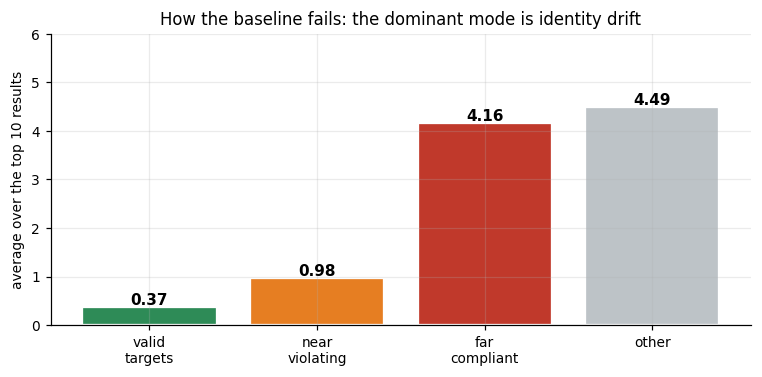

In [24]:
# ---------------------------------------------------------------- FIGURE: DISTRACTORS
if 'counts' in dir():
    short_labels = ["valid\ntargets", "near\nviolating", "far\ncompliant", "other"]
    colours = ["#2e8b57", "#e67e22", "#c0392b", "#bdc3c7"]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    bars = ax.bar(short_labels, counts / n_ref, color=colours, edgecolor="white", lw=1.5)
    for bar, v in zip(bars, counts / n_ref):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                f"{v:.2f}", ha="center", fontsize=10, fontweight="bold")
    ax.set_ylabel("average over the top 10 results")
    ax.set_title("How the baseline fails: the dominant mode is identity drift")
    ax.set_ylim(0, 6)
    plt.tight_layout()
    plt.show()

The dominant failure mode is **identity drift** (far-but-compliant), not the failure to satisfy
the conditions (near-but-violating). Any weight on the query vector improves one side and
worsens the other: the twelve closed avenues of sec. 6 are as many points on the same
one-parameter frontier.

### 5.4 The bottleneck was the data: the max_sources curve

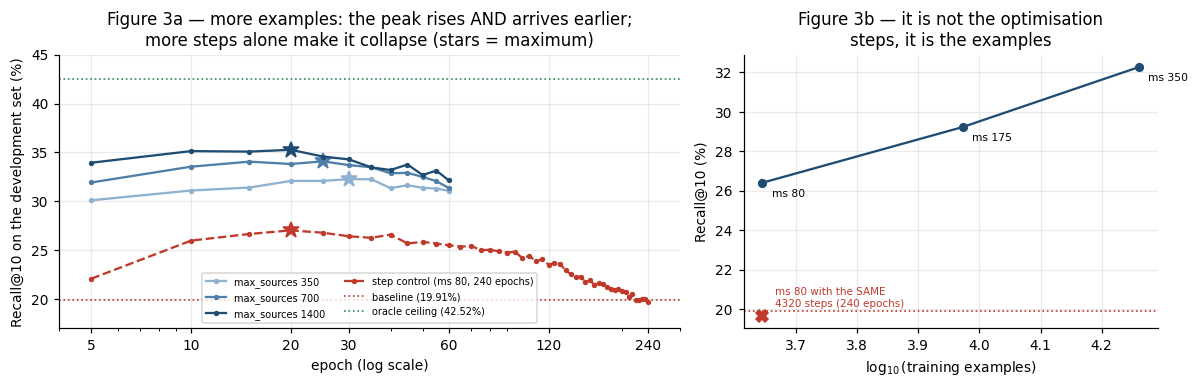

level,examples,steps,dev @ep60,peak on dev
max_sources 350,18222,4320,31.06%,32.26%
max_sources 700,35011,8220,31.34%,34.08%
max_sources 1400,63569,14940,32.12%,35.26%
"step control (ms 80, 240 epochs)",4422,4320,19.66%,27.01%


In [25]:
f_night = ROOT / "esperimenti/notte/notte_20260829-0227.json"
if not f_night.exists():
    print("PLACEHOLDER: esperimenti/notte/notte_20260829-0227.json not found.")
else:
    N = json.load(open(f_night))
    curve = N["fase1_curva"]
    BASE_DEV = N["baseline_dev_r10"]

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6),
                                 gridspec_kw={"width_ratios": [1.5, 1]})
    colours = {"max_sources 350": "#8fb2d0", "max_sources 700": "#4f7fa8",
               "max_sources 1400": "#1f4c73",
               "controllo passi (ms 80, 240 epoche)": "#c0392b"}
    for name, r in curve.items():
        pts = [(h["epoca"], h["r10_dev"]) for h in r["storia"] if "r10_dev" in h]
        if not pts:
            continue
        x, y = zip(*pts)
        style = "--" if "controllo" in name else "-"
        lab = name if "controllo" not in name else "step control (ms 80, 240 epochs)"
        a1.plot(x, y, style, color=colours[name], lw=1.5, label=lab, marker="o", ms=2.5)
        j = int(np.argmax(y))
        a1.plot(x[j], y[j], "*", color=colours[name], ms=11)
    a1.axhline(BASE_DEV, color="#c0392b", lw=1.1, ls=":", label="baseline (19.91%)")
    a1.axhline(42.52, color="#2e8b57", lw=1.1, ls=":", label="oracle ceiling (42.52%)")
    # logarithmic axis: the step control runs for 240 epochs, the three levels for 60. On a
    # linear axis the control would be TRUNCATED at its peak, which is exactly the wrong
    # reading: that model rises to 27% and then COLLAPSES below the baseline.
    a1.set_xscale("log")
    a1.set_xlim(4, 300)
    a1.set_xticks([5, 10, 20, 30, 60, 120, 240])
    a1.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
    a1.set_xlabel("epoch (log scale)")
    a1.set_ylabel("Recall@10 on the development set (%)")
    a1.set_title("Figure 3a — more examples: the peak rises AND arrives earlier;\n"
                 "more steps alone make it collapse (stars = maximum)")
    a1.legend(fontsize=6.4, loc="lower center", ncol=2)
    a1.set_ylim(17, 45)

    levels = [("80", 26.40, 4422), ("175", 29.22, 9388), ("350", 32.26, 18222)]
    a2.plot([np.log10(n) for _, _, n in levels], [v for _, v, _ in levels], "o-",
            color="#1f4c73", ms=5)
    for lab, v, n in levels:
        a2.annotate(f"ms {lab}", (np.log10(n), v), textcoords="offset points",
                    xytext=(6, -9), fontsize=7)
    a2.axhline(BASE_DEV, color="#c0392b", lw=1.1, ls=":")
    a2.plot(np.log10(4422), 19.66, "X", color="#c0392b", ms=8)
    a2.annotate("ms 80 with the SAME\n4320 steps (240 epochs)", (np.log10(4422), 19.66),
                textcoords="offset points", xytext=(8, 6), fontsize=6.8, color="#c0392b")
    a2.set_xlabel(r"$\log_{10}$(training examples)")
    a2.set_ylabel("Recall@10 (%)")
    a2.set_title("Figure 3b — it is not the optimisation\nsteps, it is the examples")
    plt.tight_layout()
    plt.show()

    rows = []
    for name, r in curve.items():
        peak = max((h["r10_dev"] for h in r["storia"] if "r10_dev" in h), default=float("nan"))
        # il nome e' una chiave del JSON di risultato, che resta in italiano apposta:
        # si traduce a stampa, come la legenda della figura qui sopra
        etichetta = ("step control (ms 80, 240 epochs)" if "controllo" in name
                     else name)
        rows.append([etichetta, r["n_esempi"], r["n_passi"], f"{r['dev_r10']:.2f}%",
                     f"{peak:.2f}%"])
    table(rows, ["level", "examples", "steps", "dev @ep60", "peak on dev"])

The parameter `max_sources` (references per query at training time) was stuck at 80. Raising it:

- **From 80 to 350**: a single model goes from 26.40% to 32.26% (+5.86pp)
- What matters is the **number of examples**, not which queries (null difference, p = 0.48)
- **It is not the optimisation steps**: the same number of steps at level 80 gives 19.66%, below
  the baseline

### 5.5 Bagging: sample diversity, not seed diversity

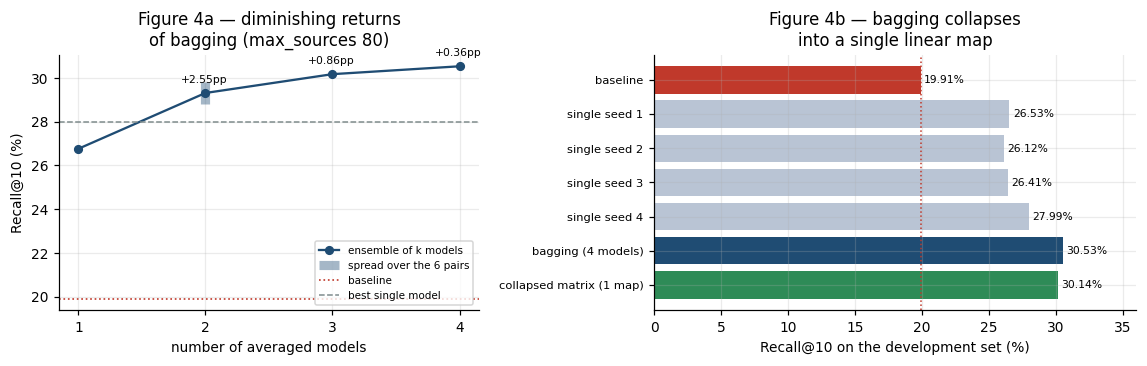

mean of the 4 single models 26.76%   ->   bagging 30.53% (+3.76pp)
collapsed matrix 30.14%: 96% of the gain at the baseline's inference cost instead of x4
R^2 of the map on the averaged output: 0.9949
algebraic check  max|W_ensemble - W_mean_of_fits| = 1.5e-07   (expected ~0: the ridge is linear in the target)


In [26]:
f_bag = ROOT / "contributo-candidato/multiseed/bagging_lineare.json"
B = json.load(open(f_bag)) if f_bag.exists() else None

# ensemble returns curve, from docs/piano-interpretabilita.md sec. 6e
# (mean over all combinations of k models among the 4 available)
CURVE_K = {1: 26.76, 2: 29.31, 3: 30.17, 4: 30.53}
K2_MIN, K2_MAX = 28.81, 29.82

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.4),
                             gridspec_kw={"width_ratios": [1, 1.15]})
ks = sorted(CURVE_K)
a1.plot(ks, [CURVE_K[k] for k in ks], "o-", color="#1f4c73", ms=5,
        label="ensemble of k models")
a1.vlines(2, K2_MIN, K2_MAX, color="#1f4c73", alpha=0.4, lw=6,
          label="spread over the 6 pairs")
if B:
    a1.axhline(B["r10"]["baseline"], color="#c0392b", lw=1.1, ls=":", label="baseline")
    a1.axhline(max(v for k, v in B["r10"].items() if k.startswith("singolo")),
               color="#7f8c8d", lw=1.0, ls="--", label="best single model")
for k in ks[1:]:
    a1.annotate(f"{CURVE_K[k] - CURVE_K[k - 1]:+.2f}pp", (k, CURVE_K[k]),
                textcoords="offset points", xytext=(-16, 7), fontsize=7)
a1.set_xticks(ks)
a1.set_xlabel("number of averaged models")
a1.set_ylabel("Recall@10 (%)")
a1.set_title("Figure 4a — diminishing returns\nof bagging (max_sources 80)")
a1.legend(fontsize=6.8, loc="lower right")

if B:
    names = ["baseline"] + [f"singolo seed {s}" for s in B["seeds"]] + \
            ["BAGGING (4 modelli)", "MATRICE collassata"]
    val = [B["r10"][n] for n in names]
    col = ["#c0392b"] + ["#b9c4d4"] * 4 + ["#1f4c73", "#2e8b57"]
    a2.barh(range(len(names)), val, color=col)
    a2.set_yticks(range(len(names)))
    a2.set_yticklabels([n.replace("BAGGING (4 modelli)", "bagging (4 models)")
                        .replace("MATRICE collassata", "collapsed matrix (1 map)")
                        .replace("singolo seed", "single seed")
                        for n in names], fontsize=7.5)
    a2.axvline(B["r10"]["baseline"], color="#c0392b", lw=1.0, ls=":")
    for i, v in enumerate(val):
        a2.text(v + 0.25, i, f"{v:.2f}%", va="center", fontsize=7)
    a2.set_xlim(0, 36)
    a2.invert_yaxis()
    a2.set_xlabel("Recall@10 on the development set (%)")
    a2.set_title("Figure 4b — bagging collapses\ninto a single linear map")
plt.tight_layout()
plt.show()

if B:
    print(f"mean of the 4 single models {B['media_singoli_r10']:.2f}%   ->   "
          f"bagging {B['r10']['BAGGING (4 modelli)']:.2f}% "
          f"(+{B['r10']['BAGGING (4 modelli)'] - B['media_singoli_r10']:.2f}pp)")
    print(f"collapsed matrix {B['r10']['MATRICE collassata']:.2f}%: "
          f"{100 * (B['r10']['MATRICE collassata'] - B['r10']['baseline']) / (B['r10']['BAGGING (4 modelli)'] - B['r10']['baseline']):.0f}"
          f"% of the gain at the baseline's inference cost instead of x4")
    print(f"R^2 of the map on the averaged output: {B['r2_ensemble']:.4f}")
    print(f"algebraic check  max|W_ensemble - W_mean_of_fits| = "
          f"{B['max_diff_fit_media']:.1e}   (expected ~0: the ridge is linear in the target)")

Averaging the outputs of 4 models trained on **different query samples**, the gain is
substantial: +3.76pp at max_sources 80, +5.16pp at 1400. Varying only the initialisation, the
gain is null (+0.07 / +0.49 / +0.01pp).

Bagging **collapses into a single matrix** — since every model is almost linear, the average of
the outputs is itself a linear map: 96% of the gain at the baseline's inference cost.

### 5.6 How positive and negative constraints interact

A compositional retrieval system has to say what it means to *remove* an attribute, not only to
add one — and a specification that leaves this implicit is incomplete. This subsection answers
the question with a measurement, and the answer also accounts for the residual non-linearity
left unexplained by sec. 5.1.

**The structural fact.** The delivered map is linear in $c$, so
$W_c(-c) = -W_c(c)$: the response to *"$-$eyeglasses"* is forced to be the exact opposite of the
response to *"$+$eyeglasses"*. The baseline's bipolar directions make the same assumption. But
the task is not symmetric. *"$+$eyeglasses"* names one target region; *"$-$red hair"* names
**everything else** — blond, brown, black are all valid. A map that can only push along one fixed
axis has no way to express "anything but this".

**The measurement.** If that argument is right, the collapsed matrix should lose ground
specifically on negative constraints. It does. The cleanest comparison uses **one-condition
queries only**, where the development set splits into 27 positive and 27 negative: the groups are
balanced and there is no confound with the number of conditions. The gap between the full
ensemble and its collapsed matrix is **three to ten times larger on the negative half**,
depending on the session, and the effect replicates across three independent training runs.

**It is the model, not the ensemble.** The gap could have come from averaging: twelve different
models need not be summarisable by one matrix even if each were perfectly linear. Collapsing
**each member on its own** rules this out — the per-member gap (+1.80pp) is the same size as the
ensemble's (+1.96pp), and every single member of all three sessions loses more on the negatives.

**The mechanism, and where it lives.** An index of how far the module departs from the
antisymmetry a matrix would impose is $0$ by construction for any linear map; it is 0.09 for the
original `max_sources` 80 model and **0.23** for the twelve members here, and the correction for a
negative condition is also systematically *shorter* than for the corresponding positive one. The
asymmetry is not built by modulating the text with the image — the text channel is still
essentially one fixed matrix (cosine 0.9987 across references, sec. 5.2 measured 0.9995 in the
original regime). It lives in the **reference-dependent** term: ablating the reference removes
83.5% of the gain on negative queries against 69.6% on positive ones. Across the twelve members
the antisymmetry index *predicts* where the collapsed matrix fails (Spearman $+0.678$, $p=0.015$).

**And it does not generalise.** Fed the 187 attribute directions of AwA2 and OVAD — built by the
same procedure, never seen in training — the module answers with half the magnitude and its
behaviour falls back to almost linear. How much of a new direction lies inside the subspace
spanned by the forty training directions predicts both ($\rho \approx +0.75$). This is the
mechanism behind the closed-vocabulary limit of sec. 7.1, measured without retraining.

**The answer, stated plainly.** In our framework a positive constraint and a
negative constraint do *not* act as opposite displacements along one axis. The learned module
breaks that symmetry — it applies a shorter, reference-dependent correction for subtractive
conditions — and this is precisely the component a single matrix cannot represent. We deliver the
matrix anyway because on the official benchmark the difference is 0.32pp, inside the noise; but
the asymmetry is real, measured on 24 models across three sessions, and it is where the remaining
headroom of this family of methods lies.

*Caveats.* The two groups are balanced in size but not in difficulty (baseline 21.21% on the
positive half against 33.92% on the negative one), the antisymmetry index is measured on
single-attribute conditions only, and the three-condition stratum has 15 queries. Code and result
files: `esperimenti/{linearita_per_strato, collasso_per_membro, antisimmetria_e_ablazione,
generalizza_meccanismo}.py` and the JSON files alongside them.


In [27]:
# --------------------------------------- 5.6 ASYMMETRY BETWEEN POSITIVE AND NEGATIVE CONSTRAINTS
# The tables below are read from the result files in esperimenti/, produced by the four scripts
# named in the markdown above. Those scripts need the ensemble checkpoints, which are not part
# (`*.pt`); their outputs are part of the accompanying materials, so this cell always runs.
DIR_CAR = ROOT / "esperimenti"


def carica(nome):
    f = DIR_CAR / nome
    return json.load(open(f)) if f.exists() else None


LIN = carica("linearita_per_strato.json")
if LIN:
    righe = []
    for tag in ("v1", "v2", "v3"):
        s = LIN["sessioni"].get(tag)
        if not s:
            continue
        u = s["una_condizione"]
        righe.append([tag, f"{u['n_positive']} + {u['n_negative']}",
                      f"{u['divario_positive_pp']:+.2f}pp", f"{u['divario_negative_pp']:+.2f}pp",
                      f"{u['differenza_pp']:+.2f}pp",
                      "[{:+.2f}, {:+.2f}]".format(u["lo"], u["hi"]),
                      f"{u['p_permutazione']:.4f}"])
    table(righe, ["session", "queries", "gap on +attr", "gap on -attr", "difference",
                  "95% CI", "p (permutation)"],
          "What the single matrix loses, ONE-condition queries only (balanced groups)")

righe = []
for tag in ("v1", "v2", "v3"):
    C = carica(f"collasso_per_membro_{tag}.json")
    if C:
        r, e = C["riassunto"], C["ensemble"]
        righe.append([tag, r["n_membri"],
                      f"{r['membri_con_divario_maggiore_sui_negativi']}/{r['n_membri']}",
                      f"{r['asimmetria_media_pp']:+.2f}pp", f"{r['asimmetria_sd_pp']:.2f}",
                      f"{e['divario_pp']:+.2f}pp"])
if righe:
    table(righe, ["session", "members", "members losing more on -attr", "mean asymmetry",
                  "sd", "gap of the ensemble"],
          "Each member collapsed on its own: the asymmetry is in the model, not in the averaging")

A = carica("antisimmetria_e_ablazione_v3.json")
if A:
    membri = {k: v for k, v in A["antisimmetria"].items() if not k.startswith("VECCHIO")}
    vecchio = A["antisimmetria"].get("VECCHIO_max_sources_80")
    righe = [["any linear map (by construction)", "0.0000", "1.0000"]]
    if vecchio:
        righe.append(["MLP at max_sources 80 (sec. 4.5)",
                      f"{vecchio['indice']:.4f}", f"{vecchio['rapporto_lunghezze']:.4f}"])
    righe.append([f"MLP of the final session, mean over {len(membri)}",
                  f"{A['indice_medio_membri']:.4f}",
                  f"{np.mean([v['rapporto_lunghezze'] for v in membri.values()]):.4f}"])
    table(righe, ["", "antisymmetry index", "||t(-d)|| / ||t(+d)||"],
          "How far the module departs from the symmetry a matrix would impose")

    righe = []
    for nome in ("+attributo", "-attributo", "TUTTE"):
        v = A["ablazione_reference"].get(nome)
        if v:
            eng = {"+attributo": "+attr", "-attributo": "-attr", "TUTTE": "all queries"}[nome]
            righe.append([eng, v["n"], f"{v['baseline']:.2f}%", f"{v['ablato']:.2f}%",
                          f"{v['intero']:.2f}%", f"{v['guadagno_ablato_pp']:+.2f}pp",
                          f"{v['guadagno_intero_pp']:+.2f}pp", f"{v['quota_persa_pct']:.1f}%"])
    table(righe, ["queries", "n", "baseline", "reference ablated", "full model",
                  "gain, ablated", "gain, full", "share of gain lost"],
          "Where the asymmetry lives: replacing the reference input with the mean reference")

G = carica("generalizza_meccanismo_v3.json")
if G:
    ordine = ["CelebA (VISTI)", "AwA2 (mai visti)", "OVAD (mai visti)", "tutti i MAI VISTI"]
    eng = {"CelebA (VISTI)": "CelebA (SEEN in training)", "AwA2 (mai visti)": "AwA2 (never seen)",
           "OVAD (mai visti)": "OVAD (never seen)", "tutti i MAI VISTI": "all NEVER SEEN"}
    righe = [[eng[k], G["gruppi"][k]["n"], f"{G['gruppi'][k]['quota_in_span']:.3f}",
              f"{G['gruppi'][k]['indice_antisimmetria']:.4f}",
              f"{G['gruppi'][k]['norma_risposta']:.4f}"]
             for k in ordine if k in G["gruppi"]]
    table(righe, ["directions", "n", "fraction in-span", "antisymmetry index",
                  "norm of the response"],
          "The mechanism does not survive on attributes never seen in training")
    v = G["visti_contro_mai_visti"]
    print(f"seen more asymmetric than never seen: p = {v['p_mannwhitney']:.1e}   "
          f"({v['indice_visti']:.4f} against {v['indice_mai_visti']:.4f}), "
          f"{v['membri_concordi']}/{v['n_membri']} members agree")
    print(f"among the never seen, the in-span fraction predicts the asymmetry "
          f"(rho {v['in_span_predice_asimmetria']['rho']:+.3f}) and the strength of the "
          f"response (rho {v['in_span_predice_norma']['rho']:+.3f}), both p < 0.0001")

session,queries,gap on +attr,gap on -attr,difference,95% CI,p (permutation)
v1,27 + 27,+1.44pp,+4.13pp,+2.69pp,"[+0.79, +4.62]",0.0040
v2,27 + 27,+1.68pp,+5.76pp,+4.08pp,"[+2.32, +5.96]",0.0000
v3,27 + 27,+0.29pp,+2.96pp,+2.67pp,"[+1.16, +4.24]",0.0006


session,members,members losing more on -attr,mean asymmetry,sd,gap of the ensemble
v1,6,6/6,+2.80pp,1.01,+2.13pp
v2,6,6/6,+3.53pp,0.86,+4.62pp
v3,12,12/12,+1.69pp,0.76,+1.96pp


,antisymmetry index,||t(-d)|| / ||t(+d)||
any linear map (by construction),0.0000,1.0000
MLP at max_sources 80 (sec. 4.5),0.0897,0.9203
"MLP of the final session, mean over 12",0.2313,0.8152


queries,n,baseline,reference ablated,full model,"gain, ablated","gain, full",share of gain lost
+attr,27,21.21%,27.63%,42.31%,+6.42pp,+21.10pp,69.6%
-attr,27,33.92%,36.30%,48.30%,+2.37pp,+14.38pp,83.5%
all queries,101,19.91%,28.75%,41.25%,+8.83pp,+21.33pp,58.6%


directions,n,fraction in-span,antisymmetry index,norm of the response
CelebA (SEEN in training),40,1.000,0.2313,1.7093
AwA2 (never seen),85,0.578,0.0967,0.7758
OVAD (never seen),102,0.632,0.1117,0.8812
all NEVER SEEN,187,0.607,0.1048,0.8333


seen more asymmetric than never seen: p = 8.9e-20   (0.2313 against 0.1048), 12/12 members agree
among the never seen, the in-span fraction predicts the asymmetry (rho +0.751) and the strength of the response (rho +0.757), both p < 0.0001


---

## 6. The closed avenues

Twelve hypotheses measured and discarded, grouped by theme. Each one closed by a measurement,
not by an argument.

### 6.1 Weighting the conditions dynamically: the ceiling is below 1pp

The literature points to dynamic weights as the remedy for CLAY's bottleneck. The ceiling of
this family was measured with **two independent oracles**:

| hypothesis | apparent margin | real margin |
|---|---|---|
| step adapted to each reference | +6.2pp | **null** (honest oracle) |
| per-condition weights, per reference | +3.8pp | +0.1pp, not significant |
| per-condition weights, per query | +1.4pp | +0.3pp, not significant |
| calibrating the global step | +3.4pp | not significant (p = 0.109) |

**The pattern repeats**: the apparent margin came from a maximum taken over N alternatives,
evaluated on the same data used to choose it. With an honest hold-out, it vanished. The
fixed-weight sum is a **motivated choice**, not a fallback.

### 6.2 Improving the textual directions: the bottleneck was elsewhere

Seven interventions on the direction channel, all null or negative:

| intervention | outcome |
|---|---|
| orthogonal rotation (Procrustes) | null |
| interpolation over semantic neighbours | null |
| centring | null |
| visual cleaning | null |
| text→vision map learned on three domains | does not transfer |
| blending at variable dose | null |
| map fed as input to the model | **the most instructive**: the network ignored the better direction |

The most informative result is the **descriptive-prompt dissociation**: describing the attribute
(*"hair growing down the sides of the face"*) instead of naming it (*"sideburns"*) repairs the
directions (AUC 0.691 → 0.735, inverted ones 7 → 1) but **retrieval does not improve** (−0.15pp,
p = 0.73). The quality of the textual direction was not the bottleneck.

### 6.3 Alternative fusion mechanisms

| mechanism | outcome | why |
|---|---|---|
| cross-attention | +4.76pp, but **loses** against concatenation | the softmax averages the conditions |
| coordinate replacement (projection onto the text subspace) | **−4.29pp** | the subspace captures only 13.7% of an image's norm |
| module $\Phi$ producing scalars (InfoNCE) | worse | the query stays in span($r, c$), where there is no margin |

### 6.4 Filtering by attributes: it works but it changes the problem

Discarding from the gallery the images that do not satisfy the constraints and ranking the rest
by identity alone is worth +4.87pp. But with the filter active **the text encoder no longer
contributes anything** (+0.32pp, p = 0.61): the text only serves to pick which output to consult
— it is a lookup on a name, not the multimodal conditioning that is required.

What remains from this avenue is the **oracle ceiling**: with perfect constraints retrieval
reaches **42.52%** — the ceiling of the "constraint" form against the "push" form.

---

## 7. Measured limits

### 7.1 The main limit: closed vocabulary

In [28]:
splits = []
for s in range(3):
    f = ROOT / f"contributo-candidato/multiseed/heldout_seed2026_split{s}.json"
    if f.exists():
        splits.append(json.load(open(f)))

rows = []
STRATUM_EN = {"visti": "seen", "MAI VISTI": "NEVER SEEN"}
for h in splits:
    for stratum in ("visti", "MAI VISTI"):
        r = h["strati"][stratum]
        rows.append([h["split"], STRATUM_EN[stratum], r["n"], f"{r['baseline']:.2f}%",
                      f"{r['modello']:.2f}%", f"{r['delta_pp']:+.2f}pp",
                      "[{:+.2f}, {:+.2f}]".format(r["lo"], r["hi"]),
                      f"{r['p']:.4f}", f"{r['in_span']:.4f}"])
table(rows, ["split", "stratum", "n", "baseline", "model", "difference",
             "95% CI", "p", "in-span"])
print(f"\nrank of the subspace spanned by the SEEN conditions: "
      f"{splits[0]['rank_span']} out of {D} (the 30 remaining directions)")
print("attributes held out in split 0: " + ", ".join(splits[0]["holdout"]))

split,stratum,n,baseline,model,difference,95% CI,p,in-span
0,seen,52,23.22%,28.19%,+4.96pp,"[+2.44, +7.53]",0.0000,1.0000
0,NEVER SEEN,22,24.34%,19.46%,-4.88pp,"[-7.26, -2.69]",0.0000,0.6954
1,seen,49,24.56%,32.02%,+7.46pp,"[+5.07, +9.91]",0.0000,1.0000
1,NEVER SEEN,24,20.91%,16.40%,-4.51pp,"[-7.76, -1.31]",0.0047,0.6415
2,seen,47,22.96%,29.20%,+6.24pp,"[+3.52, +9.23]",0.0000,1.0000
2,NEVER SEEN,27,23.50%,15.77%,-7.73pp,"[-11.31, -4.51]",0.0000,0.6625



rank of the subspace spanned by the SEEN conditions: 30 out of 512 (the 30 remaining directions)
attributes held out in split 0: Bangs, Bushy_Eyebrows, Chubby, Goatee, Gray_Hair, Male, Mouth_Slightly_Open, Wearing_Earrings, Wearing_Necktie, Young


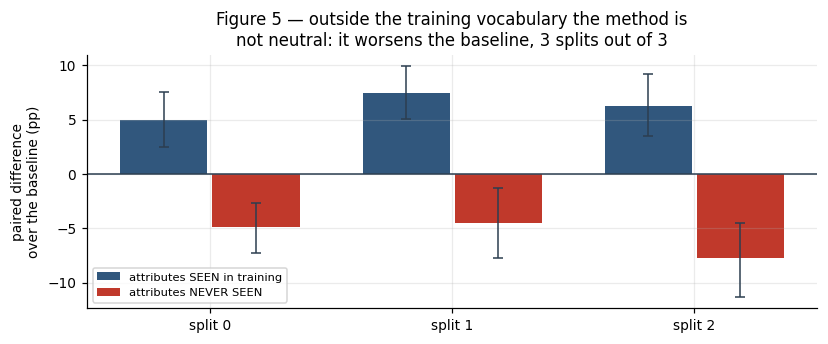

In [29]:
# ---------------------------------------------------------------- FIGURE 5
fig, ax = plt.subplots(figsize=(7.6, 3.2))
x = np.arange(len(splits))
for j, (stratum, col, off) in enumerate((("visti", "#31577d", -0.19),
                                         ("MAI VISTI", "#c0392b", 0.19))):
    v = [h["strati"][stratum]["delta_pp"] for h in splits]
    lo = [h["strati"][stratum]["delta_pp"] - h["strati"][stratum]["lo"] for h in splits]
    hi = [h["strati"][stratum]["hi"] - h["strati"][stratum]["delta_pp"] for h in splits]
    ax.bar(x + off, v, width=0.36, color=col,
           label="attributes SEEN in training" if j == 0 else "attributes NEVER SEEN")
    ax.errorbar(x + off, v, yerr=[lo, hi], fmt="none", ecolor="#2c3e50", capsize=3, lw=1)
ax.axhline(0, color="#2c3e50", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([f"split {h['split']}" for h in splits])
ax.set_ylabel("paired difference\nover the baseline (pp)")
ax.set_title("Figure 5 — outside the training vocabulary the method is\n"
             "not neutral: it worsens the baseline, 3 splits out of 3")
ax.legend(fontsize=7.5, loc="lower left")
plt.tight_layout()
plt.show()

**Not "it does not help": it does worse than the baseline** on unseen attributes, significantly
so on 3 splits out of 3 (−4.88 / −4.51 / −7.73pp).

### 7.2 The geometric mechanism

The seen conditions span a subspace of **rank 30** out of 512 dimensions. A new query made of
known attributes stays inside it with coverage exactly 1.0000 — which is why it generalises to
combinations. A new attribute falls inside it for only 64–70% of its norm: the rest ends up
where the map has never been constrained.

### 7.3 Comparison with the filtering avenue

The filter was discarded **also** because it is closed-vocabulary. So is the contribution. The
distinction: in the filter the text only served to choose which of the 40 outputs to consult;
here the text stays the input and the method composes conditions **never seen together** — the
explicit part of the specification. Both fail outside the vocabulary.

---

## 8. Results and discussion

### 8.1 Comparative table

In [30]:
ORDER = ["reference only (lower bound)", "baseline, single template",
          "baseline, with ensembling", "cross-attention (comparison)",
          "contribution, linear form", "contribution (MLP, seed 2026)",
          "DELIVERED: single matrix"]
ORDER = [n for n in ORDER if n in R_dev]

rows = []
for name in ORDER:
    r, p = macro_on(R_dev[name]), macro_on(P_dev[name])
    row = ([name] + [f"{100 * r[k]:.2f}%" for k in K_VALUES]
                  + [f"{100 * p[k]:.2f}%" for k in K_VALUES])
    if name != "baseline, with ensembling":
        s = bootstrap_paired(R_dev[name][10], R_dev["baseline, with ensembling"][10],
                             n_boot=20000, seed=0)
        row += [f"{100 * s['delta']:+.2f}pp",
                "[{:+.2f}, {:+.2f}]".format(100 * s["lo"], 100 * s["hi"]),
                f"{s['p']:.4f}"]
    else:
        row += ["—", "—", "—"]
    rows.append(row)
table(rows, ["method"] + [f"R@{k}" for k in K_VALUES] + [f"P@{k}" for k in K_VALUES]
            + ["dR@10", "95% CI", "p"],
      "DEVELOPMENT SET — 101 queries, macro-average, paired differences over the baseline")

print("\n\nOFFICIAL BENCHMARK — 13 distinct queries. It contains ONLY the baseline and its")
print("controls: this table holds the baseline and its controls; the delivered method\n      on the benchmark is in 8.2.")
rp_table(R_test, P_test, ["reference only (lower bound)", "baseline, single template",
                         "baseline, with ensembling", "DELIVERED: single matrix"], UNIQUE, "")

print("\n\nREFERENCES EXTERNAL TO THIS RUN (source declared row by row)")
rows_ref = [
    ("contribution, mean of 5 seeds", None, "+6.95pp",
     "mean, sd 0.76; every seed with CI and p<0.0001"),
    ("bagging of 4 models, max_sources 80", 30.53, "+10.61pp",
     "paired against its members (p=0.0019 on the best)"),
    ("bagging collapsed into one matrix", 30.14, "+10.23pp",
     "-0.38pp against the ensemble, p=0.037"),
    ("one model, max_sources 350", 32.26, "+12.35pp", "A SINGLE SEED, 30 fixed epochs"),
    ("max_sources 1400, honest stopping", 33.10, "+13.19pp",
     "mean of 4 seeds, NO significance test"),
    ("4 models at max_sources 1400, averaged", 36.62, "+16.71pp",
     "LEVEL: no CI against the baseline"),
    ("oracle ceiling with the true labels", 42.52, "+22.60pp", "CI [+20.31, +25.09]"),
]
table([[name, f"{v:.2f}%" if v else "26.12-27.99%", d, q] for name, v, d, q in rows_ref],
      ["configuration", "R@10 dev", "vs baseline", "quality of the number"])

method,R@1,R@5,R@10,P@1,P@5,P@10,dR@10,95% CI,p
reference only (lower bound),3.23%,10.14%,14.70%,3.23%,2.76%,2.37%,-5.22pp,"[-6.64, -3.86]",0.0000
"baseline, single template",3.97%,12.46%,18.49%,3.97%,3.26%,2.87%,-1.42pp,"[-2.14, -0.76]",0.0000
"baseline, with ensembling",4.22%,13.34%,19.91%,4.22%,3.49%,3.06%,—,—,—
cross-attention (comparison),5.04%,16.55%,24.65%,5.04%,4.38%,3.95%,+4.73pp,"[+2.78, +6.71]",0.0000
"contribution, linear form",5.72%,17.98%,26.98%,5.72%,4.80%,4.37%,+7.06pp,"[+4.91, +9.45]",0.0000
"contribution (MLP, seed 2026)",5.71%,18.22%,27.26%,5.71%,4.87%,4.43%,+7.35pp,"[+5.14, +9.74]",0.0000
DELIVERED: single matrix,8.83%,26.89%,39.29%,8.83%,7.62%,7.00%,+19.38pp,"[+16.57, +22.32]",0.0000




OFFICIAL BENCHMARK — 13 distinct queries. It contains ONLY the baseline and its
controls: this table holds the baseline and its controls; the delivered method
      on the benchmark is in 8.2.


method,R@1,R@5,R@10,P@1,P@5,P@10
reference only (lower bound),1.73%,5.29%,7.62%,1.73%,1.31%,1.09%
"baseline, single template",3.31%,8.87%,13.39%,3.31%,2.18%,1.86%
"baseline, with ensembling",3.90%,10.99%,15.92%,3.90%,2.73%,2.20%
DELIVERED: single matrix,9.37%,26.36%,37.03%,9.37%,7.67%,6.48%




REFERENCES EXTERNAL TO THIS RUN (source declared row by row)


configuration,R@10 dev,vs baseline,quality of the number
"contribution, mean of 5 seeds",26.12-27.99%,+6.95pp,"mean, sd 0.76; every seed with CI and p<0.0001"
"bagging of 4 models, max_sources 80",30.53%,+10.61pp,paired against its members (p=0.0019 on the best)
bagging collapsed into one matrix,30.14%,+10.23pp,"-0.38pp against the ensemble, p=0.037"
"one model, max_sources 350",32.26%,+12.35pp,"A SINGLE SEED, 30 fixed epochs"
"max_sources 1400, honest stopping",33.10%,+13.19pp,"mean of 4 seeds, NO significance test"
"4 models at max_sources 1400, averaged",36.62%,+16.71pp,LEVEL: no CI against the baseline
oracle ceiling with the true labels,42.52%,+22.60pp,"CI [+20.31, +25.09]"


### 8.2 How to read this table

The three qualities of number, kept distinct:
1. **Paired differences with CI and p** on the 101-query set — the rows of the first table.
2. **Differences against a reference other than the baseline** — bagging against its own members.
3. **Levels without a test** — the 33.10% and the 36.62%.

### 8.3 Per-query analysis

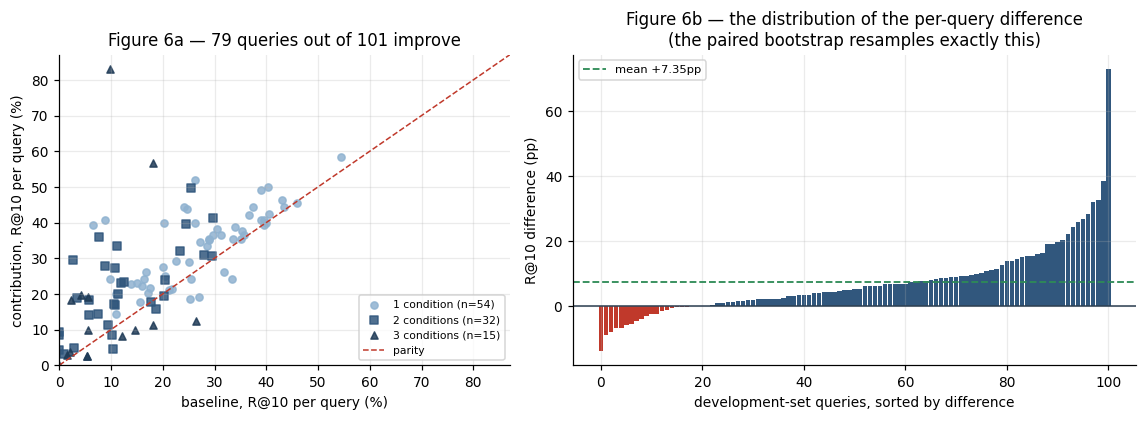

queries improved 79 / worsened 18 / unchanged 4
mean difference +7.35pp, median +5.25pp



95% CI on the baseline LEVEL       [17.39, 22.46]  (half-width 2.54pp)
95% CI on the contribution LEVEL   [24.33, 30.27]  (half-width 2.97pp)
UNPAIRED difference                expected half-width 3.91pp
PAIRED difference                  [+5.14, +9.74]  (half-width 2.30pp)

Pairing narrows the interval by a factor of 1.7: it is the between-query
variance, which dominates the levels and cancels in the difference. Two overlapping
CIs on the levels do NOT imply that the difference is null.


In [31]:
if "contribution (MLP, seed 2026)" in R_dev:
    b = np.array([v.mean() for v in R_dev["baseline, with ensembling"][10]]) * 100
    m = np.array([v.mean() for v in R_dev["contribution (MLP, seed 2026)"][10]]) * 100
    n_cond = np.array([len(e["queried"]) for e in devset])

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9),
                                 gridspec_kw={"width_ratios": [1, 1.25]})
    for n, col, mk in ((1, "#8fb2d0", "o"), (2, "#31577d", "s"), (3, "#1f3b57", "^")):
        s = n_cond == n
        a1.scatter(b[s], m[s], s=22, c=col, marker=mk, alpha=0.85,
                   label=f"{n} condition{'' if n == 1 else 's'} (n={int(s.sum())})")
    lim = max(b.max(), m.max()) * 1.05
    a1.plot([0, lim], [0, lim], color="#c0392b", lw=1, ls="--", label="parity")
    a1.set_xlim(0, lim)
    a1.set_ylim(0, lim)
    a1.set_xlabel("baseline, R@10 per query (%)")
    a1.set_ylabel("contribution, R@10 per query (%)")
    a1.set_title(f"Figure 6a — {int((m > b).sum())} queries out of {len(b)} improve")
    a1.legend(fontsize=7)

    d = m - b
    order = np.argsort(d)
    col = ["#c0392b" if v < 0 else "#31577d" for v in d[order]]
    a2.bar(np.arange(len(d)), d[order], color=col, width=0.9)
    a2.axhline(0, color="#2c3e50", lw=1)
    a2.axhline(d.mean(), color="#2e8b57", lw=1.2, ls="--",
               label=f"mean +{d.mean():.2f}pp")
    a2.set_xlabel("development-set queries, sorted by difference")
    a2.set_ylabel("R@10 difference (pp)")
    a2.set_title("Figure 6b — the distribution of the per-query difference\n"
                 "(the paired bootstrap resamples exactly this)")
    a2.legend(fontsize=7.5)
    plt.tight_layout()
    plt.show()

    print(f"queries improved {int((d > 0).sum())} / worsened {int((d < 0).sum())} / "
          f"unchanged {int((d == 0).sum())}")
    print(f"mean difference +{d.mean():.2f}pp, median +{np.median(d):.2f}pp")

    # why pairing matters: the CI of the difference is compared with the one that would be
    # obtained by combining the CIs of the two LEVELS as if they were independent
    ci_b = bootstrap_ci(R_dev["baseline, with ensembling"][10], n_boot=20000, seed=0)
    ci_m = bootstrap_ci(R_dev["contribution (MLP, seed 2026)"][10], n_boot=20000, seed=0)
    acc = bootstrap_paired(R_dev["contribution (MLP, seed 2026)"][10],
                           R_dev["baseline, with ensembling"][10], n_boot=20000, seed=0)
    non_acc = 1.96 * np.sqrt(ci_b["se"] ** 2 + ci_m["se"] ** 2) * 100
    print(f"\n95% CI on the baseline LEVEL       "
          f"[{100 * ci_b['lo']:.2f}, {100 * ci_b['hi']:.2f}]  "
          f"(half-width {100 * (ci_b['hi'] - ci_b['lo']) / 2:.2f}pp)")
    print(f"95% CI on the contribution LEVEL   "
          f"[{100 * ci_m['lo']:.2f}, {100 * ci_m['hi']:.2f}]  "
          f"(half-width {100 * (ci_m['hi'] - ci_m['lo']) / 2:.2f}pp)")
    print(f"UNPAIRED difference                expected half-width {non_acc:.2f}pp")
    print(f"PAIRED difference                  "
          f"[{100 * acc['lo']:+.2f}, {100 * acc['hi']:+.2f}]  "
          f"(half-width {100 * (acc['hi'] - acc['lo']) / 2:.2f}pp)")
    print("\nPairing narrows the interval by a factor of "
          f"{non_acc / (100 * (acc['hi'] - acc['lo']) / 2):.1f}: it is the between-query\n"
          "variance, which dominates the levels and cancels in the difference. Two overlapping\n"
          "CIs on the levels do NOT imply that the difference is null.")

### 8.4 The consolidation sessions

In [32]:
all_runs = sorted((ROOT / "scripts").glob("run_*/risultati.json"))
# the smoke-test run is not a result and must NEVER appear as one
candidates = [c for c in all_runs if c.parent.name != "run_prova"]
if len(all_runs) > len(candidates):
    print("(a one-minute smoke-test run also exists: ignored)\n")

if not candidates:
    print("The result files of the consolidation sessions are not in the materials folder.")
    print("Without them the reported configuration remains the fixed-seed model of sec. 4.5,")
    print("with its multi-seed interval alongside — the numbers of sections 5.6 and 7.1,")
    print("which are measured and do not change.")
else:
    RIS = json.load(open(candidates[-1]))
    print(f"read from: {candidates[-1].relative_to(ROOT)}")
    print(f"start {RIS['meta'].get('ultimo_avvio')}   device {RIS['meta'].get('device')}   "
          f"duration {RIS['meta'].get('durata_ore', float('nan')):.2f} h   "
          f"smoke_test={RIS['meta'].get('prova')}")
    print(f"reads the official benchmark: "
          f"{RIS['meta'].get('questo_script_legge_il_benchmark_ufficiale')}")
    print(f"baseline check on the development set: "
          f"{RIS['meta'].get('baseline_dev_r10', float('nan')):.2f}%")

    f2 = RIS["fasi"].get("f2_candidati") or RIS["fasi"].get("f2_ricerca", {})
    if f2.get("punto_scelto"):
        print(f"\nchosen point: {f2['punto_scelto']}")
        if f2.get("accordo") is not None:
            # v3: la validazione e' stata riparata (galleria disgiunta, composizione del
            # benchmark). Il collaudo era dichiarato PRIMA di guardare i numeri.
            print(f"   repair check — validation and dev choose the same candidate: "
                  f"{'YES' if f2['accordo'] else 'NO'}")
            print(f"   winner on validation: {f2.get('vincitore_validazione')}   "
                  f"on dev (not used to choose): {f2.get('vincitore_dev_non_usato')}")
        else:
            print(f"   winner on the development set, NOT used to choose: "
                  f"{f2.get('vincitore_su_dev_non_usato')}")

    f3 = RIS["fasi"].get("f3_finali") or RIS["fasi"].get("fm_minimo")
    if f3:
        print(f"\nmean of the single models: {f3['media_singoli']:.2f}%   "
              f"members: {len(f3['membri'])}")
        d = f3.get("diversita", {})
        # il nome della metrica di diversita' cambia fra le sessioni: v1 misura la
        # sovrapposizione fra i campioni di esempi, v2 e v3 quella fra i corpus
        jac = d.get("jaccard_corpus", d.get("jaccard_medio"))
        if jac is not None:
            quale = "corpora" if "jaccard_corpus" in d else "example samples"
            print(f"overlap between the members' {quale} (Jaccard): mean {jac:.3f}")
        print(f"\n{'k models':>10}{'R@10 dev':>11}{'vs baseline':>13}{'95% CI':>20}{'p':>9}")
        for k in sorted(f3["curva"], key=int):
            r = f3["curva"][k]
            v = r.get("vs_baseline", {})
            ic = "[{:+.2f}, {:+.2f}]".format(v.get("lo", float("nan")),
                                             v.get("hi", float("nan")))
            print(f"{k:>10}{r['dev_r10']:>10.2f}%{v.get('delta_pp', float('nan')):>+12.2f}pp"
                  f"{ic:>20}{v.get('p', float('nan')):>9.4f}")

    f4 = RIS["fasi"].get("f4_lineare") or RIS["fasi"].get("f4_matrice")
    if f4:
        vb, ve = f4.get("vs_baseline", {}), f4.get("vs_ensemble", {})
        print(f"\nlinear collapse: R@10 {f4['dev_r10']:.2f}%   R2 {f4['r2']:.4f}")
        print(f"   vs baseline {vb.get('delta_pp', float('nan')):+.2f}pp   "
              f"[{vb.get('lo', float('nan')):+.2f}, {vb.get('hi', float('nan')):+.2f}]   "
              f"p={vb.get('p', float('nan')):.4f}")
        print(f"   vs ensemble {ve.get('delta_pp', float('nan')):+.2f}pp   "
              f"p={ve.get('p', float('nan')):.4f}")

read from: scripts/run_colab_v3/risultati.json
start 2026-08-30T07:35:51   device cuda   duration 0.22 h   smoke_test=False
reads the official benchmark: False
baseline check on the development set: 19.91%

chosen point: {'tau': 0.01, 'ms': 1400, 'wd': 0.0001, 'hidden': 512}
   repair check — validation and dev choose the same candidate: YES
   winner on validation: B   on dev (not used to choose): B

mean of the single models: 33.97%   members: 12
overlap between the members' corpora (Jaccard): mean 0.066

  k models   R@10 dev  vs baseline              95% CI        p
         1     32.91%      +13.00pp    [+10.07, +15.97]   0.0000
         2     37.35%      +17.44pp    [+14.53, +20.49]   0.0000
         3     39.54%      +19.63pp    [+16.79, +22.56]   0.0000
         4     40.03%      +20.12pp    [+17.20, +23.21]   0.0000
         5     40.40%      +20.49pp    [+17.71, +23.43]   0.0000
         6     40.48%      +20.57pp    [+17.85, +23.38]   0.0000
         7     40.73%      +20.81

### 8.5 Qualitative examples: successes and failures

The three cases are selected with a criterion computed from the data: (1) the query where the
contribution gains the most, (2) where it loses the most, (3) the attribute with the weakest
direction.

In [33]:
from PIL import Image
import io, zipfile

SPLIT_CODE = {"train": 0, "valid": 1, "test": 2}


def find_celeba():
    """Looks for a CelebA root that contains at least list_eval_partition.txt."""
    candidates = []
    if os.environ.get("CELEBA_ROOT"):
        candidates.append(Path(os.environ["CELEBA_ROOT"]))
    candidates += [Path.home() / "datasets/celeba", ROOT / "datasets/celeba",
                   ROOT.parent / "datasets/celeba", Path("/content/celeba"),
                   Path("/content/datasets/celeba"), Path("/content/celeba/celeba")]
    for c in candidates:
        if (c / "list_eval_partition.txt").exists():
            return c
    return None


CELEBA = find_celeba()
_ZIP = None
_NAMES = {}


def split_names(split):
    """File names of the split, in the order torchvision enumerates them."""
    if split not in _NAMES:
        lines = (CELEBA / "list_eval_partition.txt").read_text().splitlines()
        _NAMES[split] = [r.split()[0] for r in lines
                         if r.strip() and int(r.split()[1]) == SPLIT_CODE[split]]
    return _NAMES[split]


def load_image(idx, split):
    """PIL image for index `idx` OF THE SPLIT, or None if unavailable."""
    global _ZIP
    if CELEBA is None:
        return None
    try:
        name = split_names(split)[idx]
    except (IndexError, OSError):
        return None
    for base in (CELEBA / "img_align_celeba", CELEBA / "img_align_celeba/img_align_celeba"):
        if (base / name).exists():
            return Image.open(base / name).convert("RGB")
    z = CELEBA / "img_align_celeba.zip"
    if z.exists():
        try:
            if _ZIP is None:
                _ZIP = zipfile.ZipFile(z)
            for inner in (f"img_align_celeba/{name}", name):
                if inner in _ZIP.namelist():
                    return Image.open(io.BytesIO(_ZIP.read(inner))).convert("RGB")
        except (zipfile.BadZipFile, KeyError, OSError):
            return None
    return None


def _some_image_available():
    """True if at least one JPEG is reachable, in the folder or inside the archive.

    The materials carry only the images the three cases below need, so probing a fixed
    index would report the images as missing even when every one that matters is there,
    and `grid` would then silently draw nothing.
    """
    if CELEBA is None:
        return False
    for base in (CELEBA / 'img_align_celeba', CELEBA / 'img_align_celeba/img_align_celeba'):
        if base.is_dir() and next(base.glob('*.jpg'), None) is not None:
            return True
    z = CELEBA / 'img_align_celeba.zip'
    if z.exists():
        try:
            with zipfile.ZipFile(z) as zf:
                return any(n.lower().endswith('.jpg') for n in zf.namelist())
        except (zipfile.BadZipFile, OSError):
            return False
    return False


IMAGES_OK = _some_image_available()
print(f"CelebA root : {CELEBA if CELEBA else 'not found'}")
print(f"images      : {'available' if IMAGES_OK else 'NOT available -> textual reading'}")
if not IMAGES_OK:
    print("\nTo get them: download img_align_celeba.zip, list_attr_celeba.txt and")
    print("list_eval_partition.txt into a folder and point CELEBA_ROOT at it.")
    print("On Colab (requires Kaggle credentials):")
    print('  !kaggle datasets download -d jessicali9530/celeba-dataset -p /content/celeba')
    print("The rest of the notebook does not depend on it: figures 1-6 and all the tables "
          "are already done.")

CelebA root : not found
images      : NOT available -> textual reading

To get them: download img_align_celeba.zip, list_attr_celeba.txt and
list_eval_partition.txt into a folder and point CELEBA_ROOT at it.
On Colab (requires Kaggle credentials):
  !kaggle datasets download -d jessicali9530/celeba-dataset -p /content/celeba
The rest of the notebook does not depend on it: figures 1-6 and all the tables are already done.


In [34]:
def analyse(entry, i_src, build_query, E, L, k=10):
    """For one reference, returns the top k results with their full diagnosis.

    For each result it reports the TWO things that define the ground truth (the provided ground-truth
    rule): whether it satisfies the +/- constraints, and the Hamming distance from the
    reference on the NON-queried attributes. A result is ground truth iff it satisfies both.
    """
    src = int(entry["sources"][i_src])
    gt = entry["gt"][i_src]
    q = build_query(E[src:src + 1], entry)
    sim = (q @ E.T)[0].clone()
    sim[src] = -torch.inf
    top = sim.topk(k).indices.tolist()

    nq = torch.tensor(entry["non_queried"])
    y_ref = L[src].bool()
    out = []
    for j in top:
        y = L[j].bool()
        ok = all(bool(y[i]) for i in entry["pos"]) and all(not bool(y[i]) for i in entry["neg"])
        ham = int((y[nq] != y_ref[nq]).sum())
        out.append({"idx": j, "compliant": ok, "hamming": ham, "gt": j in gt,
                    "sim": float(sim[j])})
    return src, out


def print_analysis(entry, i_src, methods, E, L, k=10):
    src = int(entry["sources"][i_src])
    print(f"query: {entry['query']}    reference: index {src} of the valid split    "
          f"|ground truth| = {len(entry['gt'][i_src])}")
    y_ref = L[src].bool()
    print("  the reference violates the conditions, as always in the benchmark:  "
          + ", ".join(f"{attr_names[i]}={int(y_ref[i])}" for i in entry["queried"]))
    for name, build in methods.items():
        _, res = analyse(entry, i_src, build, E, L, k)
        hit = next((p + 1 for p, r in enumerate(res) if r["gt"]), None)
        print(f"\n  {name}   ->   R@10 = {int(hit is not None)}"
              + (f"  (first ground truth at position {hit})" if hit else "")
              + f"   P@10 = {sum(r['gt'] for r in res) / k:.2f}")
        print(f"     {'pos':>4}{'index':>9}{'sim':>8}{'conditions':>12}{'Hamming':>9}"
              f"{'ground truth':>15}")
        for p, r in enumerate(res):
            print(f"     {p + 1:>4}{r['idx']:>9}{r['sim']:>8.3f}"
                  f"{('satisfied' if r['compliant'] else 'VIOLATED'):>12}"
                  f"{r['hamming']:>9}{('YES' if r['gt'] else '-'):>15}")


def grid(entry, i_src, methods, E, L, split="valid", k=10, title=""):
    """Reference + top k results for each method. Green border = ground truth."""
    if not IMAGES_OK:
        return
    n_rows = len(methods)
    fig, axes = plt.subplots(n_rows, k + 1, figsize=(1.05 * (k + 1), 1.55 * n_rows + 0.7))
    axes = np.atleast_2d(axes)
    for ri, (name, build) in enumerate(methods.items()):
        src, res = analyse(entry, i_src, build, E, L, k)
        ax = axes[ri][0]
        im = load_image(src, split)
        if im:
            ax.imshow(im)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_edgecolor("#2c3e50"); s.set_linewidth(2.2)
        ax.set_ylabel(name, fontsize=7, rotation=0, ha="right", va="center", labelpad=6)
        if ri == 0:
            ax.set_title("reference", fontsize=7)
        for p, r in enumerate(res):
            ax = axes[ri][p + 1]
            im = load_image(r["idx"], split)
            if im:
                ax.imshow(im)
            ax.set_xticks([]); ax.set_yticks([])
            col = "#2e8b57" if r["gt"] else "#c0392b"
            for s in ax.spines.values():
                s.set_edgecolor(col); s.set_linewidth(2.6)
            ax.set_xlabel(f"{'OK' if r['compliant'] else 'viol'}  H={r['hamming']}",
                          fontsize=6, color=col, labelpad=1)
            if ri == 0:
                ax.set_title(f"#{p + 1}", fontsize=7)
    fig.suptitle(title, fontsize=8.5, y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

### 8.6 The three cases

In [35]:
# sec. 4.5 may not have been run: the absence is tolerated instead of failing with a
# NameError, so the notebook holds up even when executed cell by cell
MOD_A = globals().get("MOD_A")

if "contribution (MLP, seed 2026)" in R_dev:
    methods_q = {"baseline": build_baseline(d_ens),
                 "contribution": builder(MOD_A)}

    b_q = np.array([v.mean() for v in R_dev["baseline, with ensembling"][10]])
    m_q = np.array([v.mean() for v in R_dev["contribution (MLP, seed 2026)"][10]])
    delta_q = m_q - b_q

    def pick_reference(i_query, want_success):
        rb = R_dev["baseline, with ensembling"][10][i_query]
        rm = R_dev["contribution (MLP, seed 2026)"][10][i_query]
        d = rm - rb
        cand = np.flatnonzero(d > 0) if want_success else np.flatnonzero(d < 0)
        return int(cand[0]) if len(cand) else 0

    for label, i_query, success in (
            (f"SUCCESS — largest gain among the 101 queries ({100 * delta_q.max():+.1f}pp)",
             int(np.argmax(delta_q)), True),
            (f"FAILURE — largest loss among the 101 queries ({100 * delta_q.min():+.1f}pp)",
             int(np.argmin(delta_q)), False)):
        e = devset[i_query]
        i_src = pick_reference(i_query, success)
        print("=" * 100)
        print(label)
        print("=" * 100)
        print_analysis(e, i_src, methods_q, E_valid, L_valid)
        grid(e, i_src, methods_q, E_valid, L_valid, "valid",
             title=f"{label}   —   query '{e['query']}'")
        print()

SUCCESS — largest gain among the 101 queries (+73.2pp)
query: -Smiling, +Eyeglasses, +Wearing_Hat    reference: index 624 of the valid split    |ground truth| = 15
  the reference violates the conditions, as always in the benchmark:  Eyeglasses=0, Wearing_Hat=0, Smiling=1

  baseline   ->   R@10 = 0   P@10 = 0.00
      pos    index     sim  conditions  Hamming   ground truth
        1     3689   0.466    VIOLATED        6              -
        2    17137   0.444    VIOLATED        3              -
        3     5128   0.440    VIOLATED        7              -
        4    10036   0.439    VIOLATED        3              -
        5    11925   0.436    VIOLATED       10              -
        6     2797   0.434    VIOLATED        6              -
        7    14056   0.433   satisfied        8              -
        8     5638   0.427    VIOLATED        6              -
        9     1240   0.427    VIOLATED        4              -
       10    11828   0.425    VIOLATED        3        

In [36]:
# --- third case: a weak direction, from the full-pool set ----------------------------------
f_full = ROOT / "celeba_devset_valid_full.json"
if "contribution (MLP, seed 2026)" in R_dev and f_full.exists():
    devset_full = load_benchmark(str(f_full), attr_names)
    worst = int(np.nanargmin(auc_e))
    touching = [e for e in devset_full if worst in e["queried"]]
    if not touching:                    # fallback: the weakest one actually present
        present = {i for e in devset_full for i in e["queried"]}
        worst = min(present, key=lambda i: auc_e[i] if auc_e[i] == auc_e[i] else 1.0)
        touching = [e for e in devset_full if worst in e["queried"]]
    e = max(touching, key=lambda x: len(x["sources"]))
    print("=" * 100)
    print(f"WEAK DIRECTION — '{attr_names[worst]}', AUC {auc_e[worst]:.3f} "
          f"(< 0.5: the textual direction predicts the OPPOSITE of the label)")
    print("query from the full-pool set, excluded from the development set by construction")
    print("=" * 100)
    print_analysis(e, 0, methods_q, E_valid, L_valid)
    grid(e, 0, methods_q, E_valid, L_valid, "valid",
         title=f"WEAK DIRECTION — query '{e['query']}', "
               f"AUC({attr_names[worst]}) = {auc_e[worst]:.3f}")
    print("\nOn an inverted direction the contribution has nothing to start from: the vector c")
    print("points the wrong way, and the linear map W_c can only propagate it.")
    print("This is also why the development set excludes these attributes: on them ALL methods")
    print("stay at the floor, and queries where no method stands out add noise to the")
    print("macro-average without adding discriminative power.")

WEAK DIRECTION — 'Narrow_Eyes', AUC 0.429 (< 0.5: the textual direction predicts the OPPOSITE of the label)
query from the full-pool set, excluded from the development set by construction
query: +Narrow_Eyes    reference: index 43 of the valid split    |ground truth| = 9
  the reference violates the conditions, as always in the benchmark:  Narrow_Eyes=0

  baseline   ->   R@10 = 0   P@10 = 0.00
      pos    index     sim  conditions  Hamming   ground truth
        1    19308   0.634    VIOLATED        5              -
        2    16008   0.620    VIOLATED        5              -
        3     9285   0.616    VIOLATED        4              -
        4     6983   0.609    VIOLATED        1              -
        5    16021   0.607    VIOLATED        3              -
        6     2882   0.606    VIOLATED        6              -
        7     2014   0.605    VIOLATED        3              -
        8     3147   0.601    VIOLATED        2              -
        9    16892   0.601    VIOLA

### 8.7 The two questions this work set out to answer

**Question 1 — is dynamic weighting of the conditions the lever?** The ceiling of this family is below 1pp,
measured with two independent oracles. The fixed-weight sum is a motivated choice.

**Question 2 — can the pre-SVD concatenation bottleneck be overcome?** The method beats everything we built, but
the mechanism is not the expected one: the fusion stays additive, the head is almost linear, and
the bulk of the gain comes from the reference. The bottleneck was not the fusion — it was the
conditioning on the reference, which the baseline ignores.

---

## 9. Conclusion

We set out to replace the rigid concatenation of textual and visual embeddings with a
conditioning mechanism able to weigh several constraints against one another. What we ended up
delivering is considerably smaller than what we started building, and that is itself the main
finding of this work.

**The method.** A single matrix $W \in \mathbb{R}^{1025 \times 512}$, applied to the
concatenation of the reference embedding, the signed sum of the textual conditions, and a bias
term:

$$
q \;=\; \operatorname{normalize}\bigl(r + [\,r\,;\,c\,;\,1\,]\,W\bigr)
$$

Both CLIP encoders stay frozen throughout, the gallery is embedded once and never re-encoded,
and retrieval remains a dot product against those fixed vectors. At query time the method costs
the baseline plus one matrix product.

**The result.** On the official test split the matrix raises Recall@10 from 15.92% to
**37.03%** (+21.11pp, 95% CI [+12.87, +29.75], $p < 0.0001$), improving on the baseline in 12 of
the 13 queries, and Precision@10 from 2.20% to 6.48%. On the 101-query development set it
reaches 39.29%, against an oracle ceiling of 42.52% — the level a *perfect* constraint filter
would reach using the true labels.

**Learning inside a frozen embedding space.** The matrix trains **524,800 parameters, 0.347% of
the 151,277,313 of CLIP ViT-B/32**, and no weight of CLIP is ever updated. In effect this is an
adaptation carried out entirely in the embedding space: the model is left as it is, and what is
learned is how to *move* within the representation it already produces. That most of the
achievable gain survives this restriction is not obvious in advance, and the size of the gain is
the argument that the restriction is not expensive.

**What it took to find out.** The method was not designed as a matrix. It began as a small
non-linear module, and the matrix appeared only because we stopped pushing the number and
characterised what the module was actually computing; sec. 4.9 traces that chain step by step.
Three of the findings are worth carrying beyond this dataset:

- the gain does not come from better textual directions — seven separate interventions on that
  channel produced nothing — but from **conditioning on the reference image**, which the
  arithmetic baseline ignores entirely (sec. 5.2);
- **positive and negative constraints are not symmetric**, and the one component a single matrix
  cannot express is precisely the one that handles the negative ones (sec. 5.6);
- the ceiling of this whole family is the **closed vocabulary**: on attribute directions never
  seen during training the mechanism does not fire, in proportion to how far the new direction
  falls outside the subspace the training data spanned (sec. 5.6 and 7.1).

**Relation to prior work.** Baldrati, Bertini, Uricchio and Del Bimbo (CVPR 2022) address the
same problem — conditioned and composed retrieval built on CLIP features — with a two-stage
procedure whose first stage **fine-tunes CLIP's encoder**, after which a combiner network is
trained on the adapted features. That route was not available to us: the features here are
frozen by construction, and re-encoding a 200k-image gallery was beyond the compute at our
disposal. Their work is nevertheless the closest validation of the direction we took — a learned
combination of CLIP features is a sound way to attack composed retrieval — and the comparison
sharpens what our result adds: how much of that gain is reachable **without touching the encoder
at all**. Read together, the two suggest that encoder fine-tuning and embedding-space
conditioning are complementary rather than competing.

**What we would do next.** The limit is measured and its mechanism is understood, which makes
the next step concrete rather than speculative: widening the span of the training directions, or
detecting at query time when a condition falls outside that span and falling back to the
baseline for that condition alone. Both are cheap to test, and neither requires touching CLIP.


---

## 10. Compliance, declared limits, attribution

### 10.1 Protocol compliance

The evaluation protocol is the one defined by the provided materials — the benchmark file, its
ground-truth rule and its metrics. This table states, element by element, what was followed and
where.

| protocol element | where | status |
|---|---|---|
| CLIP ViT-B/32 from HuggingFace, both encoders frozen | sec. 3.1 | ⚠️ same weights, but the features were extracted with OpenAI's `clip` rather than `transformers`: see the note below |
| visual database extracted **once** and kept frozen | sec. 11.1 | ✅ never re-encoded |
| zero-shot baseline by latent arithmetic, as the lower bound | sec. 3 | ✅ 15.92% on the benchmark |
| evaluation restricted to the source indices given in the benchmark file | sec. 8.1 | ✅ 13 distinct queries |
| **Recall@K and Precision@K** at K = 1, 5, 10 | sec. 8.1 | ✅ both reported |
| a fusion module for $T^{+}$ and $T^{-}$ | sec. 4 | ✅ delivered as a single linear map, obtained by collapsing the module (sec. 4.9) |
| improving on the pre-SVD concatenation | sec. 4, 6.4 | ⚠️ achieved (+21.11pp), but the mechanism is not the expected one: see 8.7 |
| built from scratch, no third-party code as a starting point | the whole notebook | ✅ every component written for this project |

**One formal non-compliance, declared.** The embeddings in `embeddings/*.pt` were extracted on
13/05 with OpenAI's `clip` library rather than with `transformers`. The weights are the same and
a sanity check (mean zero-shot AUC 0.786) confirms the files are valid;
The extraction code in sec. 11.1 does the required thing. But the re-extraction **was
not carried out**, and this must be stated rather than passed over in silence.

### 10.2 What the project did NOT do, and what remains open

- **The benchmark budget is now exhausted.** It is one evaluation per method, and it was
  spent twice: on 25/08 for the zero-shot filter, with a negative outcome (13.00% against
  the baseline's 15.92%), and on 30/08 for the delivered matrix (37.03%). The
  configuration was frozen and the prediction deposited in writing *before* measuring;
  the prediction turned out to be too conservative. No further method can be evaluated
  there without breaking the rule the project set itself.
- **The paired bootstrap of the ensemble against the baseline on the 36.62%** was not computed,
  and the reason is that the per-source outcomes and the checkpoints of those models were not
  kept.
- **Lookup on individual attributes is not ruled out.** Lookup on combinations is, by
  construction. For individual ones it requires inspecting $W_c$ directly: it is algebra,
  not an experiment, but it has not been done.
- **Bagging on unseen attributes has not been tested the right way**: on the leave-attribute-out
  splits only the initialisation was varied (+0.07pp), not the query sample. It is the only open
  experiment that could turn a measured gain into a general one.
- **An ensemble of well-stopped models** (rather than over-trained at 60 epochs) has not been
  measured.
- **CLAY was not implemented** (4.3), so we do not claim to beat it.

### 10.3 A note on the working method

The commit log shows a recurring pattern worth reporting explicitly: **the people in the group
overturn their own results and write it down.** Arianna corrects her own +3.4pp on the
calibrated step; nilo dismantles his own explanation of the discrepancy at K=1 and sees his own
plan A falsified by the group; Filippo records a wrong prediction of his own (he had argued that
bagging and data would not add up; they do) and overturns one of his own conclusions on the
out-of-span agreement (+0.7217 → +0.0776, it was a measurement artefact).

Eight overturned results are documented **together with the measurement that overturns them**.
A complete fact-check, which marks every claim of the project as *holds* / *to be softened* /
*not reproducible* / *missing*, was carried out before writing this report, and is the
source of this notebook.

### 10.4 Attribution

57 commits between 06/05 and 29/08/2026.

**Filippo Roseghini** — the candidate contribution (`contributo-candidato/cross_attention.py`,
`cross_attention_v2.py`): the first method in the project that clearly beats the baseline. The
discarded avenues 1–4 (attribute filtering, bilinear map, plan A, descriptive prompts), and with
them the complete version of the **42.52% oracle ceiling**. Avenue 5 and the decomposition of the
distractors into two populations. The 29/08 session on `max_sources` and on bagging at high data.
The correction on the out-of-span agreement.

**Arianna Schiavi** — the benchmark protocol and the exact reconstruction of
the official ground truth. The corrected baseline: prompt ensembling, and the discovery that the
baseline was underestimated by three points. The **honest oracles** that closed the step,
per-condition weights and dynamic conditioning. The interpretability plan and its execution
(`interpretabilita.py`, `esperimento_layernorm.py`). The 28/08 session in `esperimenti/`: eleven
scripts, the closed-vocabulary diagnosis, the decomposition into the two channels, the
multi-domain experiment, bagging.

**nilo netti** — the development-set machinery and `bootstrap_paired`: the 101-query set and the
hierarchical paired bootstrap, the instrument everything else rests on. The full-pool set. The
multi-seed replication of the contribution (`multiseed.py`, `mappa_lineare.py`,
`attributi_heldout.py`) and with it the closed-vocabulary limit and the methodological correction
on `lstsq`. Bagging collapsed into a single matrix. The embeddings of the three domains (AwA2,
OVAD). `oracle_ceilings.py`, `zeroshot_filter.py`. The Recall/Precision correction in notebooks
02–05.

### 10.5 References

- Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision*
  (CLIP) — sec. *Prompt engineering and ensembling*, the source of the template ensembling in
  sec. 3.
- Lim, Hyoseok, Park, Oh (2026), *CLAY: Conditional Visual Similarity Modulation in
  Vision-Language Embedding Space*, CVPR — the projection framework discussed in 4.3.
- Berasi, Farina, Mancini, Ricci, Strisciuglio (2025), *Not only text: Exploring compositionality
  of visual representations in vision-language models* (GDE), CVPR.
- Liu, Luo, Wang, Tang (2015), *Deep Learning Face Attributes in the Wild* (CelebA), ICCV.
- Baldrati, Bertini, Uricchio, Del Bimbo (2022), *Effective Conditioned and Composed Image
  Retrieval Combining CLIP-Based Features*, CVPR, pp. 21466–21474 — the closest prior work: same
  problem on CLIP features, but with the encoder fine-tuned (see sec. 9).
- Bravo, Mittal, Ging, Brox (2023), *Open-Vocabulary Attribute Detection* (OVAD), CVPR — the
  second domain of sec. 6.3.
- Xian, Lampert, Schiele, Akata (2018), *Zero-shot learning — a comprehensive evaluation* (AwA2),
  TPAMI.
- Alhamoud et al. (2025), *Vision-Language Models Do Not Understand Negation* (NegBench), CVPR —
  on the asymmetric treatment of $T^{-}$, which our framework does **not** model (bipolar
  directions assume that negating is the exact opposite of asserting).
- *Same Concept, Different Directions: Cross-Modal Feature Heterogeneity in Sparse Autoencoders*
  (arXiv:2606.29888) — a plausible and citable explanation for the seven attributes with an
  inverted textual direction (sec. 3.2).
- Karthik et al. (2024), *Vision-by-Language for Training-Free Compositional Image Retrieval*
  (CIReVL), ICLR — a point of comparison that moves composition into language; we do not follow
  it because it requires an LLM and a captioner at query time, whereas we stay on fixed
  embeddings.

### 10.6 Accompanying materials

Everything this notebook executes is in the notebook. What travels alongside it is data: the
frozen features, the evaluation file, and the recorded outputs of the training sessions that
sec. 8 reports. The layout the setup cell expects:

```
celeba_evaluation.json              the provided evaluation queries and ground truth
celeba_devset_valid.json            the 101-query development set (built by the code in sec. 2)
celeba_devset_valid_full.json       the full 40-attribute pool, used for the weak directions
embeddings/celeba_{train,valid,test}_clip_vitb32.pt
                                    frozen CLIP ViT-B/32 features, extracted once (sec. 11.1)
esperimenti/*.json                  the characterisation results read by sec. 5.6
contributo-candidato/multiseed/     the multi-seed replication and the bagging results
run_colab_v3/                       the final consolidation session: per-source outcomes,
                                    the ensemble curve and the linear collapse
benchmark_ufficiale.json            the single evaluation on the official test split
```

In [37]:
print(f"notebook executed in {(time.time() - T_START) / 60:.1f} minutes "
      f"({'Colab' if IN_COLAB else 'local'}, "
      f"{'with' if HAS_TRAIN else 'WITHOUT'} the train-split embeddings, "
      f"CelebA images {'available' if IMAGES_OK else 'not available'}).")
print(f"implementation check: baseline "
      f"{100 * macro_on(R_dev['baseline, with ensembling'])[10]:.2f}% on the development set, "
      f"{100 * macro_on(R_test['baseline, with ensembling'], UNIQUE)[10]:.2f}% on the benchmark "
      f"(expected 19.91% and 15.92%).")

notebook executed in 2.9 minutes (local, with the train-split embeddings, CelebA images not available).
implementation check: baseline 19.91% on the development set, 15.92% on the benchmark (expected 19.91% and 15.92%).


---

## 11. Additional materials

The body of this report states its numbers and cites the file each one comes from. This section
holds what could not be run inline: the feature extraction, which needs the images and a GPU,
and the session that produced the delivered matrix, which needs about twenty minutes on a T4.
The module of sec. 4 is trained in the body, where the sections that analyse it can use it.

Nothing here is required for the report to be read. Everything here is required for it to be
believed.

### 11.1 Extracting the visual features

The features of the three CelebA splits are extracted once with CLIP ViT-B/32 and never
recomputed: the gallery is a fixed matrix, and retrieval is a dot product against it. This is
the code that produces the `embeddings/*.pt` files the setup cell looks for. It is not run here,
because it needs the images and about twenty minutes on a GPU.

```python
from transformers import CLIPModel, CLIPProcessor
from torch.utils.data import DataLoader
from torchvision.datasets import CelebA

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

for split in ("train", "valid", "test"):
    ds = CelebA(root, split=split, target_type="attr", download=False)
    embs, labels = [], []
    for images, attrs in DataLoader(ds, batch_size=256, num_workers=4):
        px = proc(images=list(images), return_tensors="pt")["pixel_values"]
        with torch.no_grad():
            embs.append(model.get_image_features(pixel_values=px))
        labels.append(attrs)
    torch.save({"embeddings": torch.cat(embs), "labels": torch.cat(labels),
                "attr_names": ds.attr_names}, f"embeddings/celeba_{split}_clip_vitb32.pt")
```

**Declared non-compliance.** The features actually used were extracted with OpenAI's original
`clip` package rather than with `transformers`. The weights are identical and a sanity check
(mean zero-shot AUC 0.786 over the forty attributes) confirms the files are valid, but the
re-extraction with `transformers` was not carried out, and the numbers in this report come from
the original files.



### 11.2 Training the delivered matrix

The matrix reported in sec. 4.9 comes from a longer session: twelve members at `max_sources`
1400, each on its own training corpus, each stopped by an honest validation set built on a
gallery it never sees, and their averaged output collapsed into a single ridge-fitted map. On a
T4 that is about twenty minutes; on a CPU it is hours, which is why it is not run inline.

The configuration, fixed and reported for reproduction:

| | |
|---|---|
| temperature $\tau$ | 0.01 |
| references per query, `max_sources` | 1400 |
| optimiser | AdamW, lr $3\cdot10^{-4}$, weight decay $10^{-4}$ |
| hidden width | 512 |
| members | 12, each with its own 20,000-image corpus and 75% of the query pool |
| stopping | honest validation, 148 queries on a disjoint 20,000-image gallery, patience 3 |
| collapse | ridge, $\lambda = 10^{-3}$, fitted on 18,397 (reference, condition) pairs from the train split |

The per-member outcomes, the ensemble curve for $k = 1 \dots 12$ and the collapse diagnostics
are in `run_colab_v3/` among the accompanying materials, and sec. 8.4 reads them.

### 11.3 The characterisation

The four analyses of sec. 5.6 — the stratified gap, the per-member collapse, the antisymmetry
index with the reference ablation, and the behaviour on unseen attribute directions — are
produced by four scripts distributed with the materials. Their outputs are the JSON files that
sec. 5.6 reads, so that section runs without re-running any of them.